# Microdata Fine-Tuning for Decision Models — Empirical Analysis

Evaluation of `KEV-0.8B`, `KEV-4B`, and `KEV-9B` across a clean 2×2 microdata fine-tuning design (`Untrained`, `Electricity`, `Drones`, and `Drones + Electricity`) using two universal metrics shared across all benchmarks: **Population Slope MSE ($\beta\text{ MSE}$)** and **Choice-Distribution KL Divergence ($\text{Choice KL}$)**. All dataset shorthands and citations are defined in **Table 0a** below.

*(Note: OLS beta-loss and KL-anchor regimes are preserved separately in `03-analysis-paper.ipynb` for the follow-up paper.)*

### Narrative Roadmap
- **Table 0a — Datasets**: Shorthand labels, citations, roles, sample sizes, and OLS slope counts.
- **Step 0 — Run & `test_best` Inventory**: Training status (`runs-rorqual/`, `runs-nibi/`) and `test_best/` completion across `Food labels`, `Vaccines`, `Consumer rights`, and `AI & offshoring`.
- **Overview — The Story at a Glance**: Table 0b, Figure 0 (change on `Flights †` vs. held-out test sets for every fine-tuned regime).
- **Step 1 — Microdata Fine-Tuning Transfers to Unseen Domains**: Table 1, Figure 1 (`Untrained` vs. `Electricity`, `Drones`, `Drones + Electricity`); Choice KL in Table A1.
- **Step 2 — Where Fine-Tuning Transfers (Attribute-Level Analysis)**: Figure 2 (`Flights †` population slopes by attribute vs. human), Table 2 & Figure 3 (`Consumer rights` Price vs. non-price attribute groups), Table 3 & Figure 4 (`AI & offshoring` Price vs. job-change attribute groups).
- **Appendix**: Full Choice KL table (Table A1) and per-attribute population slope tables for `Vaccines` (Table A2), `Flights †` (Table A3), `Consumer rights` (Table A4), and `AI & offshoring` (Table A5).

In [2]:
import json
import os
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import display

from cycler import cycler

# Repository academic palette ("lancet") & neutral tones
PALETTE_NAME = "lancet"
PALETTES = {
    "nature": ["#1B365D", "#9E2A2B", "#2E8B78", "#D9822B", "#6F5091", "#4A6F8A"],
    "lancet": ["#1B365D", "#9E2A2B", "#2E8B78", "#D9822B", "#6F5091", "#4A6F8A"],
}
NEUTRALS = {
    "text": "#2B2B2B",
    "muted": "#52514E",
    "ref_line": "#6E6A64",
    "baseline": "#9A9893",
    "grid": "#D4D2CC",
    "legend_edge": "#E0DED8",
}
PAL = PALETTES[PALETTE_NAME]
plt.rcParams["axes.prop_cycle"] = cycler(color=PAL)

pd.set_option("display.max_columns", 20)
pd.set_option("display.max_rows", 100)
pd.set_option("display.width", 240)
pd.set_option("display.max_colwidth", None)

CODE_DIR = next(
    (c for p in (Path.cwd(), *Path.cwd().parents) for c in (p, p / "code") if all((c / d).is_dir() for d in ("kev", "data", "training"))),
    None,
)
if CODE_DIR is None:
    raise RuntimeError(f"No code/ root containing kev/, data/, and training/ at or above {Path.cwd()}")

BETA_TRAINING_DIR = CODE_DIR / "train-notebooks" / "beta-training"
PAPER_DIR = BETA_TRAINING_DIR / "ms_paper_beta_loss"
PAPER_RUNS_ROOT = PAPER_DIR / "runs-rorqual"
# Regime runs pulled from each cluster; one regime run lives in exactly one of these
REGIME_RUN_ROOTS = (PAPER_DIR / "runs-rorqual", PAPER_DIR / "runs-nibi")
TEST_BEST_SUBDIR = "test_best"

os.chdir(CODE_DIR)
for _p in (str(CODE_DIR), str(CODE_DIR / "kev"), str(BETA_TRAINING_DIR), str(PAPER_DIR)):
    if _p not in sys.path:
        sys.path.insert(0, _p)

from beta_train import runs as run_store
from paper_beta import extract_step0_from_run_dir, load_paper_run

MODEL_SLUGS = ("kev-0.8b", "kev-4b", "kev-9b")
MODEL_DISPLAY = {
    "kev-0.8b": "KEV-0.8B",
    "kev-4b": "KEV-4B",
    "kev-9b": "KEV-9B",
}
VALIDATORS = ("kriner2026", "grummon2025")

REGIME_LABELS = {
    "row1_base_untrained": "Untrained",
    "row2b_wu_ce_oracle": "Electricity",
    "row3_berke_ce_only": "Drones",
    "row5_full_berke_wu_ce_oracle": "Drones + Electricity",
}
ALL_SLUGS = tuple(REGIME_LABELS.keys())
TRAINED_SLUGS = tuple(k for k in ALL_SLUGS if k != "row1_base_untrained")


def print_caption(label: str, title: str) -> None:
    """APA caption printed above a table or figure: number on one line, brief title on the next."""
    print(label)
    print(title)


def print_note(note: str) -> None:
    """APA general note printed below a table or figure."""
    print(f"Note. {note}")


def load_test_best_entry(run_or_row1_dir: Path, expected_step: int) -> dict | None:
    """Load `test_best/` (`grummon2025`, `covid`, and optional `kantorowicz2026` / `magistro2025`) and verify alignment."""
    test_dir = run_or_row1_dir / TEST_BEST_SUBDIR
    test_json = test_dir / "test.json"
    if not test_json.exists():
        return None
    metrics_csv = test_dir / "metrics.csv"
    betas_csv = test_dir / "betas.csv"
    if not metrics_csv.exists() or not betas_csv.exists():
        raise FileNotFoundError(f"Incomplete test_best directory in {test_dir}")

    test_info = json.loads(test_json.read_text(encoding="utf-8"))
    actual_step = int(test_info["checkpoint_step"])
    if actual_step != expected_step:
        raise ValueError(f"Stale test_best in {test_dir}: checkpoint_step={actual_step}, expected {expected_step}")

    metrics_df = pd.read_csv(metrics_csv).set_index("dataset")
    for ds in ("grummon2025", "covid"):
        if ds not in metrics_df.index:
            raise ValueError(f"Dataset {ds!r} missing from {metrics_csv}")

    betas_df = pd.read_csv(betas_csv)
    required_cols = {"validator", "term", "human_pop_beta", "model_pop_beta"}
    if not required_cols.issubset(betas_df.columns):
        raise ValueError(f"Missing columns in {betas_csv}: expected {required_cols}, got {set(betas_df.columns)}")

    k26_in_metrics = "kantorowicz2026" in metrics_df.index
    k26_in_betas = bool((betas_df["validator"] == "kantorowicz2026").any())
    if k26_in_metrics != k26_in_betas:
        raise ValueError(
            f"Inconsistent kantorowicz2026 state in {test_dir}: "
            f"in metrics.csv={k26_in_metrics}, in betas.csv={k26_in_betas}"
        )
    kantorowicz_betas = (
        betas_df[betas_df["validator"] == "kantorowicz2026"].set_index("term")
        if k26_in_metrics
        else None
    )

    m25_in_metrics = "magistro2025" in metrics_df.index
    m25_in_betas = bool((betas_df["validator"] == "magistro2025").any())
    if m25_in_metrics != m25_in_betas:
        raise ValueError(
            f"Inconsistent magistro2025 state in {test_dir}: "
            f"in metrics.csv={m25_in_metrics}, in betas.csv={m25_in_betas}"
        )
    magistro_betas = (
        betas_df[betas_df["validator"] == "magistro2025"].set_index("term")
        if m25_in_metrics
        else None
    )

    return {
        "metrics_df": metrics_df,
        "covid_betas": betas_df[betas_df["validator"] == "covid"].set_index("term"),
        "grummon_betas": betas_df[betas_df["validator"] == "grummon2025"].set_index("term"),
        "kantorowicz_betas": kantorowicz_betas,
        "has_kantorowicz": k26_in_metrics,
        "magistro_betas": magistro_betas,
        "has_magistro": m25_in_metrics,
    }


def find_run_dir(model_slug: str, slug: str) -> Path:
    """The regime run folder across REGIME_RUN_ROOTS; a path without run.json when the run does not exist yet."""
    found = []
    for root in REGIME_RUN_ROOTS:
        candidate = root / model_slug / slug
        if (candidate / "run.json").exists():
            found.append(candidate)
    if len(found) > 1:
        raise ValueError(f"{model_slug}/{slug} exists in more than one run root: {found}")
    if len(found) == 1:
        return found[0]
    return REGIME_RUN_ROOTS[0] / model_slug / slug


print(f"PAPER_RUNS_ROOT (Row 1): {PAPER_RUNS_ROOT}")
print(f"REGIME_RUN_ROOTS: {[str(r) for r in REGIME_RUN_ROOTS]}")

PAPER_RUNS_ROOT (Row 1): /home/dw/github/decision-models-finetuning/code/train-notebooks/beta-training/ms_paper_beta_loss/runs-rorqual
REGIME_RUN_ROOTS: ['/home/dw/github/decision-models-finetuning/code/train-notebooks/beta-training/ms_paper_beta_loss/runs-rorqual', '/home/dw/github/decision-models-finetuning/code/train-notebooks/beta-training/ms_paper_beta_loss/runs-nibi']


---
## Datasets (Table 0a)

In [3]:
from beta_ols import berke2023 as ds_berke
from beta_ols import covid as ds_covid
from beta_ols import grummon2025 as ds_grummon
from beta_ols import kantorowicz2026 as ds_kantorowicz
from beta_ols import kriner2026 as ds_kriner
from beta_ols import magistro2025 as ds_magistro
from beta_ols import wu2025 as ds_wu

DATASET_SPECS = (
    (
        "Electricity",
        "Wu (2025)",
        "Energy Research & Social Science",
        "Training (microdata)",
        "Electricity-plan conjoint: monthly bill, renewable share, local renewables",
        ds_wu,
        "CaseID",
        False,
    ),
    (
        "Drones",
        "Berke et al. (2023)",
        "Transportation Research Part C",
        "Training (microdata)",
        "Drone-delivery discrete choice: delivery fee, wait time, privacy",
        ds_berke,
        "ResponseId",
        False,
    ),
    (
        "Food labels",
        "Grummon et al. (2025)",
        "JAMA Network Open",
        "Held-out test",
        "Six-arm nutrition-label trial: front-of-package warning labels vs. control",
        ds_grummon,
        "participantid",
        True,
    ),
    (
        "Vaccines",
        "Kreps et al. (2020)",
        "JAMA Network Open",
        "Held-out test",
        "COVID-19 vaccine conjoint: efficacy, duration, side effects, FDA, origin, endorsements",
        ds_covid,
        "respondent",
        True,
    ),
    (
        "Consumer rights",
        "Kantorowicz-Reznichenko et al. (2026)",
        "Journal of Law and Empirical Analysis",
        "Held-out test",
        "Laptop & laundry-machine conjoints: price, brand, product specs, warranty, privacy, liability, conflict resolution",
        ds_kantorowicz,
        "CASEID",
        True,
    ),
    (
        "AI & offshoring",
        "Magistro et al. (2025)",
        "American Journal of Political Science",
        "Held-out test",
        "Smartphone AI & offshoring conjoint (US & Canada): price, customer service jobs, factory jobs, data science jobs",
        ds_magistro,
        "CASEID",
        True,
    ),
    (
        "Flights †",
        "Goldfarb et al. (2026)",
        "Journal of Cleaner Production",
        "Validation (selects best.pt)",
        "Flight conjoint: price, sustainable aviation fuel, airline, baggage, legroom, seat",
        ds_kriner,
        "respondent",
        True,
    ),
)

dataset_rows = []
for shorthand, citation, journal, role, task_desc, mod, resp_col, uses_slopes in DATASET_SPECS:
    choice_df = mod.load_choice_df()
    n_resp = int(choice_df[resp_col].nunique())
    n_choices = int(len(choice_df))
    if uses_slopes:
        specs = mod.regression_specs(mod.regression_rows(choice_df))
        n_slopes = sum(len(spec.target_labels) for spec in specs.values())
        slopes_str = str(n_slopes)
    else:
        slopes_str = "—"
    dataset_rows.append(
        {
            "Dataset": shorthand,
            "Citation": citation,
            "Journal": journal,
            "Role": role,
            "Choice task & key attributes": task_desc,
            "Respondents": f"{n_resp:,}",
            "Choices": f"{n_choices:,}",
            "OLS slopes": slopes_str,
        }
    )

datasets_summary_df = pd.DataFrame(dataset_rows).set_index("Dataset")
print_caption("Table 0a", "Summary of Training, Validation, and Held-Out Test Datasets")
display(datasets_summary_df)
print_note(
    "Shorthand labels in the first column are used throughout all tables and figures. "
    "Training datasets (Electricity, Drones) are used purely as respondent-level choice microdata via cross-entropy loss. "
    "OLS slopes = number of population regression slopes used for evaluation (Consumer rights spans two product conjoints of 19 slopes each = 38 total; "
    "AI & offshoring spans four country × arm regressions of 8 slopes each = 32 total). "
    "† Flights (Goldfarb et al., 2026) is the validation set used to select each run's checkpoint (best.pt)."
)

Table 0a
Summary of Training, Validation, and Held-Out Test Datasets


,Citation,Journal,Role,Choice task & key attributes,Respondents,Choices,OLS slopes
Dataset,,,,,,,
Electricity,Wu (2025),Energy Research & Social Science,Training (microdata),"Electricity-plan conjoint: monthly bill, renewable share, local renewables","1,861","18,591",—
Drones,Berke et al. (2023),Transportation Research Part C,Training (microdata),"Drone-delivery discrete choice: delivery fee, wait time, privacy","3,625","36,297",—
Food labels,Grummon et al. (2025),JAMA Network Open,Held-out test,Six-arm nutrition-label trial: front-of-package warning labels vs. control,"5,633","33,798",5
Vaccines,Kreps et al. (2020),JAMA Network Open,Held-out test,"COVID-19 vaccine conjoint: efficacy, duration, side effects, FDA, origin, endorsements","1,971","9,855",11
Consumer rights,Kantorowicz-Reznichenko et al. (2026),Journal of Law and Empirical Analysis,Held-out test,"Laptop & laundry-machine conjoints: price, brand, product specs, warranty, privacy, liability, conflict resolution","2,242","26,823",38
AI & offshoring,Magistro et al. (2025),American Journal of Political Science,Held-out test,"Smartphone AI & offshoring conjoint (US & Canada): price, customer service jobs, factory jobs, data science jobs","5,525","21,005",32
Flights †,Goldfarb et al. (2026),Journal of Cleaner Production,Validation (selects best.pt),"Flight conjoint: price, sustainable aviation fuel, airline, baggage, legroom, seat","1,000","5,000",12


Note. Shorthand labels in the first column are used throughout all tables and figures. Training datasets (Electricity, Drones) are used purely as respondent-level choice microdata via cross-entropy loss. OLS slopes = number of population regression slopes used for evaluation (Consumer rights spans two product conjoints of 19 slopes each = 38 total; AI & offshoring spans four country × arm regressions of 8 slopes each = 32 total). † Flights (Goldfarb et al., 2026) is the validation set used to select each run's checkpoint (best.pt).


---
## Step 0 — Run & `test_best` Inventory

In [4]:
def collect_model_regimes(
    model_slug: str,
) -> tuple[pd.DataFrame, dict[str, pd.DataFrame], dict[str, pd.DataFrame], dict[str, pd.DataFrame], pd.DataFrame]:
    model_dir = PAPER_RUNS_ROOT / model_slug
    existing_dirs = []
    for s in TRAINED_SLUGS:
        candidate = find_run_dir(model_slug, s)
        if (candidate / "run.json").exists():
            existing_dirs.append(candidate)
    if len(existing_dirs) == 0:
        raise FileNotFoundError(f"No canonical microdata runs for {model_slug} in {REGIME_RUN_ROOTS}")

    step0 = extract_step0_from_run_dir(existing_dirs[0], VALIDATORS)
    step0_kriner_betas = step0["betas_by_validator"]["kriner2026"][["human_pop_beta", "model_pop_beta"]].copy()

    covid_betas_by_slug: dict[str, pd.DataFrame] = {}
    kantorowicz_betas_by_slug: dict[str, pd.DataFrame] = {}
    magistro_betas_by_slug: dict[str, pd.DataFrame] = {}

    row1_tb = load_test_best_entry(model_dir / "row1_base_untrained", expected_step=0)
    if row1_tb is not None:
        g0_tb = float(row1_tb["metrics_df"].loc["grummon2025", "beta_mse"])
        g0_val = step0["metrics"]["grummon2025/beta_mse"]
        if abs(g0_tb - g0_val) > 2e-4:
            raise ValueError(f"{model_slug} Untrained Grummon mismatch: val={g0_val:.6f} vs test_best={g0_tb:.6f}")
        row1_grummon_mse = g0_tb
        row1_grummon_kl = float(row1_tb["metrics_df"].loc["grummon2025", "kl_loss"])
        row1_covid_mse = float(row1_tb["metrics_df"].loc["covid", "beta_mse"])
        row1_covid_kl = float(row1_tb["metrics_df"].loc["covid", "kl_loss"])
        covid_betas_by_slug["row1_base_untrained"] = row1_tb["covid_betas"]
        if row1_tb["has_kantorowicz"]:
            row1_k26_mse = float(row1_tb["metrics_df"].loc["kantorowicz2026", "beta_mse"])
            row1_k26_kl = float(row1_tb["metrics_df"].loc["kantorowicz2026", "kl_loss"])
            kantorowicz_betas_by_slug["row1_base_untrained"] = row1_tb["kantorowicz_betas"]
        else:
            row1_k26_mse = np.nan
            row1_k26_kl = np.nan
        if row1_tb["has_magistro"]:
            row1_m25_mse = float(row1_tb["metrics_df"].loc["magistro2025", "beta_mse"])
            row1_m25_kl = float(row1_tb["metrics_df"].loc["magistro2025", "kl_loss"])
            magistro_betas_by_slug["row1_base_untrained"] = row1_tb["magistro_betas"]
        else:
            row1_m25_mse = np.nan
            row1_m25_kl = np.nan
        row1_pending = [
            tag
            for ok, tag in ((row1_tb["has_kantorowicz"], "k26"), (row1_tb["has_magistro"], "m25"))
            if not ok
        ]
        row1_progress = "step 0 [test_best ✓]" if not row1_pending else f"step 0 [test_best: {', '.join(row1_pending)} pending]"
    else:
        row1_grummon_mse = step0["metrics"]["grummon2025/beta_mse"]
        row1_grummon_kl = step0["metrics"]["grummon2025/kl_loss"]
        row1_covid_mse = np.nan
        row1_covid_kl = np.nan
        row1_k26_mse = np.nan
        row1_k26_kl = np.nan
        row1_m25_mse = np.nan
        row1_m25_kl = np.nan
        row1_progress = "step 0 [test_best pending]"

    rows = [
        {
            "slug": "row1_base_untrained",
            "regime": REGIME_LABELS["row1_base_untrained"],
            "progress": row1_progress,
            "kriner_mse": step0["metrics"]["kriner2026/beta_mse"],
            "kriner_kl": step0["metrics"]["kriner2026/kl_loss"],
            "grummon_mse": row1_grummon_mse,
            "grummon_kl": row1_grummon_kl,
            "covid_mse": row1_covid_mse,
            "covid_kl": row1_covid_kl,
            "kantorowicz_mse": row1_k26_mse,
            "kantorowicz_kl": row1_k26_kl,
            "magistro_mse": row1_m25_mse,
            "magistro_kl": row1_m25_kl,
        }
    ]

    for slug in TRAINED_SLUGS:
        run_dir = find_run_dir(model_slug, slug)
        if not (run_dir / "run.json").exists():
            rows.append(
                {
                    "slug": slug,
                    "regime": REGIME_LABELS[slug],
                    "progress": "—",
                    "kriner_mse": np.nan,
                    "kriner_kl": np.nan,
                    "grummon_mse": np.nan,
                    "grummon_kl": np.nan,
                    "covid_mse": np.nan,
                    "covid_kl": np.nan,
                    "kantorowicz_mse": np.nan,
                    "kantorowicz_kl": np.nan,
                    "magistro_mse": np.nan,
                    "magistro_kl": np.nan,
                }
            )
            continue

        run_info = run_store.read_run_json(run_dir)
        raw_status = run_info["status"]
        result = load_paper_run(run_dir)
        steps_done = len(result.step_df)
        best_step = int(result.best["step"])

        if raw_status != run_store.STATUS_FINISHED:
            rows.append(
                {
                    "slug": slug,
                    "regime": REGIME_LABELS[slug],
                    "progress": f"{raw_status} (@{best_step}/{steps_done})",
                    "kriner_mse": np.nan,
                    "kriner_kl": np.nan,
                    "grummon_mse": np.nan,
                    "grummon_kl": np.nan,
                    "covid_mse": np.nan,
                    "covid_kl": np.nan,
                    "kantorowicz_mse": np.nan,
                    "kantorowicz_kl": np.nan,
                    "magistro_mse": np.nan,
                    "magistro_kl": np.nan,
                }
            )
            continue

        k_metrics, _ = result.best_validation["kriner2026"]
        tb_entry = load_test_best_entry(run_dir, expected_step=best_step)
        if tb_entry is not None:
            g_mse = float(tb_entry["metrics_df"].loc["grummon2025", "beta_mse"])
            g_kl = float(tb_entry["metrics_df"].loc["grummon2025", "kl_loss"])
            if "grummon2025" in result.best_validation:
                g_val = float(result.best_validation["grummon2025"][0]["beta_mse"])
                if abs(g_mse - g_val) > 2e-4:
                    raise ValueError(f"{model_slug}/{slug} Grummon mismatch: val={g_val:.6f} vs test_best={g_mse:.6f}")
            c_mse = float(tb_entry["metrics_df"].loc["covid", "beta_mse"])
            c_kl = float(tb_entry["metrics_df"].loc["covid", "kl_loss"])
            covid_betas_by_slug[slug] = tb_entry["covid_betas"]
            if tb_entry["has_kantorowicz"]:
                k26_mse = float(tb_entry["metrics_df"].loc["kantorowicz2026", "beta_mse"])
                k26_kl = float(tb_entry["metrics_df"].loc["kantorowicz2026", "kl_loss"])
                kantorowicz_betas_by_slug[slug] = tb_entry["kantorowicz_betas"]
            else:
                k26_mse = np.nan
                k26_kl = np.nan
            if tb_entry["has_magistro"]:
                m25_mse = float(tb_entry["metrics_df"].loc["magistro2025", "beta_mse"])
                m25_kl = float(tb_entry["metrics_df"].loc["magistro2025", "kl_loss"])
                magistro_betas_by_slug[slug] = tb_entry["magistro_betas"]
            else:
                m25_mse = np.nan
                m25_kl = np.nan
            pending = [
                tag
                for ok, tag in ((tb_entry["has_kantorowicz"], "k26"), (tb_entry["has_magistro"], "m25"))
                if not ok
            ]
            tb_tag = "[test_best ✓]" if not pending else f"[test_best: {', '.join(pending)} pending]"
        else:
            c_mse = np.nan
            c_kl = np.nan
            k26_mse = np.nan
            k26_kl = np.nan
            m25_mse = np.nan
            m25_kl = np.nan
            tb_tag = "[test_best pending]"
            if "grummon2025" in result.best_validation:
                g_mse = float(result.best_validation["grummon2025"][0]["beta_mse"])
                g_kl = float(result.best_validation["grummon2025"][0]["kl_loss"])
            else:
                g_valid = result.val_history_df["grummon2025/beta_mse"].dropna()
                g_step = int(g_valid.index[np.abs(g_valid.index.to_numpy() - best_step).argmin()])
                g_mse = float(g_valid.loc[g_step])
                g_kl = float(result.val_history_df.loc[g_step, "grummon2025/kl_loss"])

        rows.append(
            {
                "slug": slug,
                "regime": REGIME_LABELS[slug],
                "progress": f"{raw_status} (@{best_step}/{steps_done}) {tb_tag}",
                "kriner_mse": float(k_metrics["beta_mse"]),
                "kriner_kl": float(k_metrics["kl_loss"]),
                "grummon_mse": g_mse,
                "grummon_kl": g_kl,
                "covid_mse": c_mse,
                "covid_kl": c_kl,
                "kantorowicz_mse": k26_mse,
                "kantorowicz_kl": k26_kl,
                "magistro_mse": m25_mse,
                "magistro_kl": m25_kl,
            }
        )

    return (
        pd.DataFrame(rows).set_index("slug"),
        covid_betas_by_slug,
        kantorowicz_betas_by_slug,
        magistro_betas_by_slug,
        step0_kriner_betas,
    )


regimes_by_model: dict[str, pd.DataFrame] = {}
covid_betas_by_model: dict[str, dict[str, pd.DataFrame]] = {}
kantorowicz_betas_by_model: dict[str, dict[str, pd.DataFrame]] = {}
magistro_betas_by_model: dict[str, dict[str, pd.DataFrame]] = {}
step0_kriner_betas_by_model: dict[str, pd.DataFrame] = {}
for model_slug in MODEL_SLUGS:
    (
        regimes_by_model[model_slug],
        covid_betas_by_model[model_slug],
        kantorowicz_betas_by_model[model_slug],
        magistro_betas_by_model[model_slug],
        step0_kriner_betas_by_model[model_slug],
    ) = collect_model_regimes(model_slug)

status_grid = pd.DataFrame(
    {MODEL_DISPLAY[m]: regimes_by_model[m].loc[list(ALL_SLUGS), "progress"].values for m in MODEL_SLUGS},
    index=[REGIME_LABELS[s] for s in ALL_SLUGS],
)
status_grid.index.name = "Regime"
display(status_grid)

,KEV-0.8B,KEV-4B,KEV-9B
Regime,,,
Untrained,step 0 [test_best ✓],step 0 [test_best: m25 pending],step 0 [test_best: m25 pending]
Electricity,finished (@640/1395) [test_best ✓],finished (@416/1395) [test_best: m25 pending],finished (@928/1395) [test_best: m25 pending]
Drones,finished (@1152/2730) [test_best ✓],finished (@544/2730) [test_best: m25 pending],finished (@256/2730) [test_best: m25 pending]
Drones + Electricity,finished (@1600/4125) [test_best ✓],finished (@1472/4125) [test_best: m25 pending],finished (@1600/4125) [test_best: m25 pending]


---
## Shared Formatting & Plotting Helpers

In [5]:
from matplotlib.ticker import FuncFormatter, NullFormatter

BASE_SLUG = "row1_base_untrained"
MSE_SCALE = 1000.0
STORY_COLUMNS = (
    ("grummon", "Food labels"),
    ("covid", "Vaccines"),
    ("kantorowicz", "Consumer rights"),
    ("magistro", "AI & offshoring"),
    ("kriner", "Flights †"),
)
STORY_LABELS = dict(REGIME_LABELS)
STORY_COLORS = {
    "row1_base_untrained": NEUTRALS["baseline"],
    "row2b_wu_ce_oracle": PAL[2],
    "row3_berke_ce_only": PAL[4],
    "row5_full_berke_wu_ce_oracle": PAL[0],
}
ROLES_NOTE = (
    "Food labels (Grummon et al., 2025), Vaccines (Kreps et al., 2020), Consumer rights (Kantorowicz-Reznichenko et al., 2026), and AI & offshoring (Magistro et al., 2025) are held-out test sets; "
    "† Flights (Goldfarb et al., 2026) is the validation set and selects each run's checkpoint (best.pt)."
)
TABLE_LETTERS = "abcdefgh"


def run_is_finished(run_dir: Path) -> bool:
    """True when the run folder has run.json and the run finished; paper assets report finished runs only."""
    if not (run_dir / "run.json").exists():
        return False
    return run_store.read_run_json(run_dir)["status"] == run_store.STATUS_FINISHED


def build_metric_table(models: tuple[str, ...], slugs: tuple[str, ...], metric_suffix: str, columns: tuple) -> pd.DataFrame:
    """Numeric table (model × regime slug, by dataset column) for one metric; regimes without a finished run are NaN."""
    frames = []
    for model_slug in models:
        sub = regimes_by_model[model_slug].reindex(list(slugs))
        frame_columns = {}
        for ds_key, ds_label in columns:
            frame_columns[ds_label] = sub[f"{ds_key}_{metric_suffix}"].astype(float)
        frame = pd.DataFrame(frame_columns)
        frame.index = pd.MultiIndex.from_tuples(
            [(MODEL_DISPLAY[model_slug], s) for s in sub.index],
            names=["Model", "Trained on"],
        )
        frames.append(frame)
    return pd.concat(frames)


def format_mse_cell(value: float, base_value: float, slug: str) -> str:
    if np.isnan(value):
        return "NaN"
    scaled = value * MSE_SCALE
    if slug == BASE_SLUG:
        return f"{scaled:.2f}"
    change_pct = 100.0 * (value - base_value) / base_value
    return f"{scaled:.2f} ({change_pct:+.0f}%)"


def format_pct(value: float) -> str:
    if np.isnan(value):
        return "NaN"
    return f"{value:+.0f}%"


def best_cell_css(values: pd.DataFrame) -> pd.DataFrame:
    """Bold the lowest trained value per model and dataset column when it improves on Untrained."""
    css = pd.DataFrame("", index=values.index, columns=values.columns)
    for model_name in values.index.get_level_values("Model").unique():
        model_block = values.xs(model_name, level="Model", drop_level=False)
        trained_block = model_block.drop(index=BASE_SLUG, level="Trained on")
        for col in values.columns:
            if trained_block[col].notna().sum() < 2:
                continue
            best_index = trained_block[col].idxmin()
            best_value = float(trained_block.loc[best_index, col])
            base_value = float(values.loc[(model_name, BASE_SLUG), col])
            if not np.isnan(base_value) and best_value < base_value:
                css.loc[best_index, col] = "font-weight: bold"
    return css


def relabel_rows(frame: pd.DataFrame) -> pd.DataFrame:
    out = frame.copy()
    out.index = pd.MultiIndex.from_tuples(
        [(model_name, STORY_LABELS[slug]) for model_name, slug in out.index],
        names=out.index.names,
    )
    return out


def build_mse_styler(models: tuple[str, ...], slugs: tuple[str, ...], columns: tuple):
    """β MSE ×10³ with % change vs. untrained; bold = best trained value per model and column."""
    values = build_metric_table(models, slugs, "mse", columns)
    text = pd.DataFrame("", index=values.index, columns=values.columns)
    for model_name, slug in values.index:
        for col in values.columns:
            value = float(values.loc[(model_name, slug), col])
            base_value = float(values.loc[(model_name, BASE_SLUG), col])
            text.loc[(model_name, slug), col] = format_mse_cell(value, base_value, slug)
    css = relabel_rows(best_cell_css(values))
    return relabel_rows(text).style.apply(lambda _frame: css, axis=None)


def plot_dot_panels(models: tuple[str, ...], slugs: tuple[str, ...], datasets: tuple, y_offsets: dict, x_ticks: tuple, reference_slug: str) -> None:
    """One panel per model: datasets on y, β MSE ×10³ on a shared log x axis; untrained = open circle."""
    if reference_slug not in slugs:
        raise ValueError(f"reference_slug {reference_slug!r} not in slugs {slugs}")
    if y_offsets[reference_slug] != y_offsets[BASE_SLUG]:
        raise ValueError(f"reference {reference_slug!r} offset != untrained offset; the bar would not meet the dot")
    fig, axes = plt.subplots(
        1,
        len(models),
        figsize=(3.6 * len(models) + 4.0, 0.78 * len(datasets) + 1.5),
        sharex=True,
        sharey=True,
        squeeze=False,
    )
    axes = axes[0]
    y_positions = np.arange(len(datasets))

    for ax, model_slug in zip(axes, models):
        sub = regimes_by_model[model_slug].reindex(list(slugs))
        if len(datasets) >= 2 and datasets[-1][0] == "kriner":
            ax.axhline(len(datasets) - 1.5, color=NEUTRALS["grid"], linestyle="--", linewidth=0.9, zorder=0)
        for y, (ds_key, _) in zip(y_positions, datasets):
            base_value = float(sub.loc[BASE_SLUG, f"{ds_key}_mse"]) * MSE_SCALE
            end_value = float(sub.loc[reference_slug, f"{ds_key}_mse"]) * MSE_SCALE
            bar_y = y + y_offsets[BASE_SLUG]
            if not np.isnan(base_value) and not np.isnan(end_value):
                ax.plot([end_value, base_value], [bar_y, bar_y], color=NEUTRALS["grid"], linewidth=2.0, zorder=1)

        for slug in slugs:
            values = [float(sub.loc[slug, f"{ds_key}_mse"]) * MSE_SCALE for ds_key, _ in datasets]
            y_shifted = y_positions + y_offsets[slug]
            if slug == BASE_SLUG:
                ax.scatter(values, y_shifted, s=60, facecolors="white", edgecolors=NEUTRALS["text"], linewidths=1.4, zorder=3, label=STORY_LABELS[slug])
            else:
                ax.scatter(values, y_shifted, s=60, color=STORY_COLORS[slug], edgecolors=NEUTRALS["text"], linewidths=0.5, zorder=3, label=STORY_LABELS[slug])

        ax.set_xscale("log")
        ax.set_xticks(x_ticks)
        ax.set_xticklabels([f"{t:g}" for t in x_ticks])
        ax.xaxis.set_minor_formatter(NullFormatter())
        ax.set_title(MODEL_DISPLAY[model_slug], fontsize=11, fontweight="bold")
        ax.set_xlabel("β MSE (×10³)")
        ax.grid(axis="x", color=NEUTRALS["grid"], alpha=0.6, which="both")

    axes[0].set_yticks(y_positions)
    axes[0].set_yticklabels([label for _, label in datasets])
    axes[0].set_ylim(-0.5, len(datasets) - 0.5)
    axes[0].invert_yaxis()
    axes[-1].legend(fontsize=8.5, loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)
    fig.tight_layout()
    plt.show()

---
## Overview — The Story at a Glance (Table 0b, Figure 0)

Table 0b
Overview of Microdata Fine-Tuning Regimes


Training microdata                          KEV-0.8B              KEV-4B              KEV-9B          
                     Electricity (18,591 choices) Drones (36,297 choices) Flights † Test mean Flights † Test mean Flights † Test mean
Trained on                                                                                                                           
Electricity                                     ✓                              -50%      -32%      -58%       NaN      -57%       NaN
Drones                                                                  ✓      -45%      -30%      -76%       NaN      -49%       NaN
Drones + Electricity                            ✓                       ✓      -74%      -46%      -82%       NaN      -82%       NaN

Note. Values are percentage changes in population β MSE versus the untrained model; negative is better. Test mean = mean of the changes on Food labels, Vaccines, Consumer rights, and AI & offshoring. Food labels (Grummon et al., 2025), Vaccines (Kreps et al., 2020), Consumer rights (Kantorowicz-Reznichenko et al., 2026), and AI & offshoring (Magistro et al., 2025) are held-out test sets; † Flights (Goldfarb et al., 2026) is the validation set and selects each run's checkpoint (best.pt). NaN = held-out test evaluation not finished yet.
Figure 0
Change in β MSE on Flights † Versus the Held-Out Test Sets


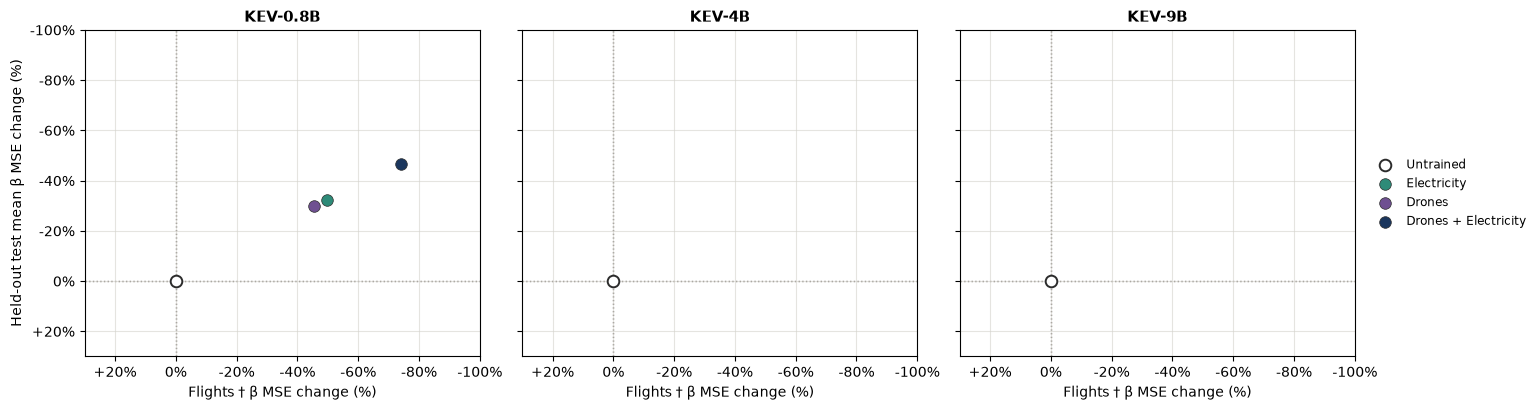

Note. Each point is one fine-tuning regime. x-axis: Flights †; y-axis: mean of Food labels, Vaccines, Consumer rights, and AI & offshoring. Both axes show the percentage change in population β MSE versus the untrained model (open circle at the origin) and are reversed, so up and right are better. Food labels (Grummon et al., 2025), Vaccines (Kreps et al., 2020), Consumer rights (Kantorowicz-Reznichenko et al., 2026), and AI & offshoring (Magistro et al., 2025) are held-out test sets; † Flights (Goldfarb et al., 2026) is the validation set and selects each run's checkpoint (best.pt). Missing points: held-out test evaluations not finished yet.


In [6]:
OVERVIEW_MODELS = MODEL_SLUGS
OVERVIEW_SLUGS = TRAINED_SLUGS
OVERVIEW_DATA_USED = {
    "row2b_wu_ce_oracle": ("✓", ""),
    "row3_berke_ce_only": ("", "✓"),
    "row5_full_berke_wu_ce_oracle": ("✓", "✓"),
}
TEST_KEYS = ("grummon", "covid", "kantorowicz", "magistro")


def pct_change_vs_base(model_slug: str, slug: str, ds_key: str) -> float:
    sub = regimes_by_model[model_slug]
    base_value = float(sub.loc[BASE_SLUG, f"{ds_key}_mse"])
    value = float(sub.loc[slug, f"{ds_key}_mse"])
    return 100.0 * (value - base_value) / base_value


def test_mean_pct_change(model_slug: str, slug: str) -> float:
    """Mean over the four held-out test sets of the % change in β MSE vs. untrained."""
    return float(np.mean([pct_change_vs_base(model_slug, slug, ds_key) for ds_key in TEST_KEYS]))


overview_rows = []
for slug in OVERVIEW_SLUGS:
    elec_micro, drones_micro = OVERVIEW_DATA_USED[slug]
    row = {
        ("", "Trained on"): STORY_LABELS[slug],
        ("Training microdata", "Electricity (18,591 choices)"): elec_micro,
        ("Training microdata", "Drones (36,297 choices)"): drones_micro,
    }
    for model_slug in OVERVIEW_MODELS:
        row[(MODEL_DISPLAY[model_slug], "Flights †")] = format_pct(pct_change_vs_base(model_slug, slug, "kriner"))
        row[(MODEL_DISPLAY[model_slug], "Test mean")] = format_pct(test_mean_pct_change(model_slug, slug))
    overview_rows.append(row)

overview_df = pd.DataFrame(overview_rows)
overview_df.columns = pd.MultiIndex.from_tuples(overview_df.columns)
overview_df = overview_df.set_index([("", "Trained on")])
overview_df.index.name = "Trained on"
print_caption("Table 0b", "Overview of Microdata Fine-Tuning Regimes")
display(overview_df)
print_note(
    "Values are percentage changes in population β MSE versus the untrained model; negative is better. "
    "Test mean = mean of the changes on Food labels, Vaccines, Consumer rights, and AI & offshoring. "
    f"{ROLES_NOTE} NaN = held-out test evaluation not finished yet."
)

OVERVIEW_AXIS_LIMITS = (30.0, -100.0)
signed_pct_formatter = FuncFormatter(lambda v, _: "0%" if v == 0 else f"{v:+.0f}%")
print_caption("Figure 0", "Change in β MSE on Flights † Versus the Held-Out Test Sets")

fig, axes = plt.subplots(1, len(OVERVIEW_MODELS), figsize=(3.9 * len(OVERVIEW_MODELS) + 3.8, 4.2), sharex=True, sharey=True)
for ax, model_slug in zip(axes, OVERVIEW_MODELS):
    ax.axhline(0.0, color=NEUTRALS["ref_line"], linestyle=":", linewidth=1.0, zorder=1)
    ax.axvline(0.0, color=NEUTRALS["ref_line"], linestyle=":", linewidth=1.0, zorder=1)
    ax.scatter([0.0], [0.0], s=70, facecolors="white", edgecolors=NEUTRALS["text"], linewidths=1.4, zorder=3, label=STORY_LABELS[BASE_SLUG])
    for slug in OVERVIEW_SLUGS:
        x_value = pct_change_vs_base(model_slug, slug, "kriner")
        y_value = test_mean_pct_change(model_slug, slug)
        ax.scatter([x_value], [y_value], s=70, color=STORY_COLORS[slug], edgecolors=NEUTRALS["text"], linewidths=0.5, zorder=3, label=STORY_LABELS[slug])
    ax.set_title(MODEL_DISPLAY[model_slug], fontsize=11, fontweight="bold")
    ax.set_xlabel("Flights † β MSE change (%)")
    ax.xaxis.set_major_formatter(signed_pct_formatter)
    ax.yaxis.set_major_formatter(signed_pct_formatter)
    ax.grid(color=NEUTRALS["grid"], alpha=0.6)
    ax.set_xlim(OVERVIEW_AXIS_LIMITS)
    ax.set_ylim(OVERVIEW_AXIS_LIMITS)

axes[0].set_ylabel("Held-out test mean β MSE change (%)")
axes[-1].legend(fontsize=8.5, loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)
fig.tight_layout()
plt.show()
print_note(
    "Each point is one fine-tuning regime. x-axis: Flights †; y-axis: mean of Food labels, Vaccines, Consumer rights, and AI & offshoring. "
    "Both axes show the percentage change in population β MSE versus the untrained model (open circle at the origin) and are reversed, so up and right are better. "
    f"{ROLES_NOTE} Missing points: held-out test evaluations not finished yet."
)

---
## Step 1 — Microdata Fine-Tuning Transfers to Unseen Domains (Table 1, Figure 1)

In [7]:
print_caption("Table 1", "Population β MSE After Microdata Fine-Tuning")
display(build_mse_styler(MODEL_SLUGS, ALL_SLUGS, STORY_COLUMNS))
print_note(
    "Values are population β MSE ×10³, with the percentage change versus the untrained model in parentheses; lower is better. "
    "Bold marks the lowest trained value per model and column when it improves on Untrained. "
    f"{ROLES_NOTE} NaN = held-out test evaluation not finished yet."
)

Table 1
Population β MSE After Microdata Fine-Tuning


Note. Values are population β MSE ×10³, with the percentage change versus the untrained model in parentheses; lower is better. Bold marks the lowest trained value per model and column when it improves on Untrained. Food labels (Grummon et al., 2025), Vaccines (Kreps et al., 2020), Consumer rights (Kantorowicz-Reznichenko et al., 2026), and AI & offshoring (Magistro et al., 2025) are held-out test sets; † Flights (Goldfarb et al., 2026) is the validation set and selects each run's checkpoint (best.pt). NaN = held-out test evaluation not finished yet.


Figure 1
Microdata Fine-Tuning Across Benchmarks


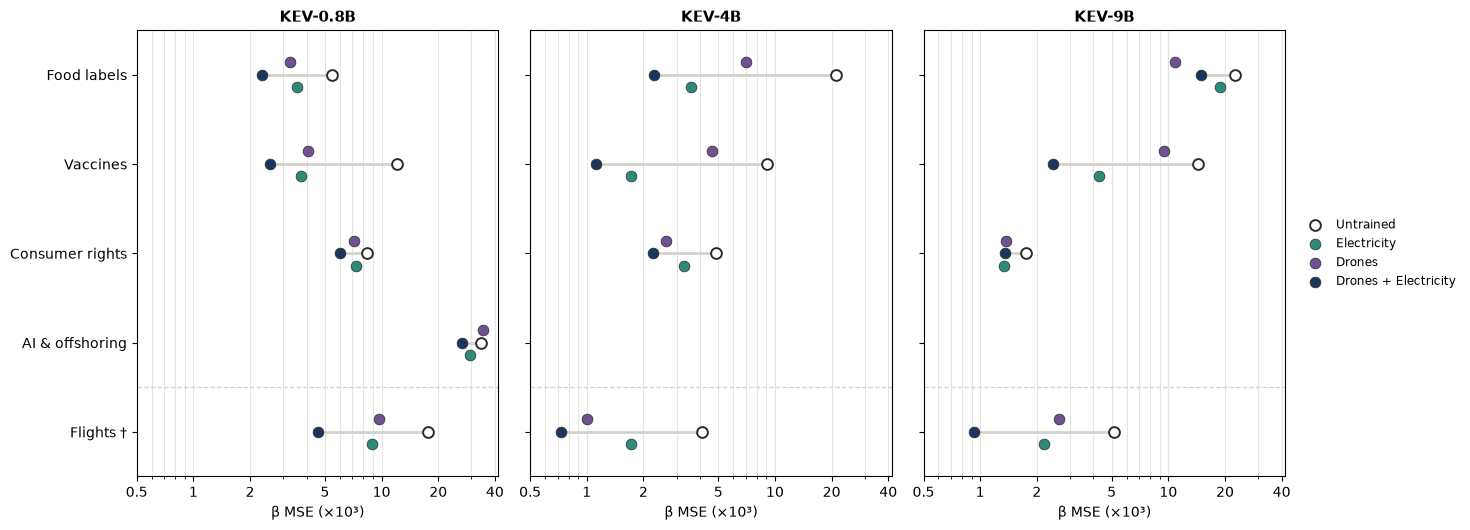

Note. Open circles are the untrained model; filled circles are fine-tuned runs. Population β MSE ×10³ on a shared log scale; lower is better. The grey bar joins the untrained model to Drones + Electricity. The dashed horizontal line separates held-out test sets (above) from the validation set (below). Food labels (Grummon et al., 2025), Vaccines (Kreps et al., 2020), Consumer rights (Kantorowicz-Reznichenko et al., 2026), and AI & offshoring (Magistro et al., 2025) are held-out test sets; † Flights (Goldfarb et al., 2026) is the validation set and selects each run's checkpoint (best.pt). Missing points: held-out test evaluations not finished yet.


In [8]:
print_caption("Figure 1", "Microdata Fine-Tuning Across Benchmarks")
plot_dot_panels(
    models=MODEL_SLUGS,
    slugs=ALL_SLUGS,
    datasets=STORY_COLUMNS,
    y_offsets={
        "row1_base_untrained": 0.0,
        "row2b_wu_ce_oracle": 0.14,
        "row3_berke_ce_only": -0.14,
        "row5_full_berke_wu_ce_oracle": 0.0,
    },
    x_ticks=(0.5, 1, 2, 5, 10, 20, 40),
    reference_slug="row5_full_berke_wu_ce_oracle",
)
print_note(
    "Open circles are the untrained model; filled circles are fine-tuned runs. Population β MSE ×10³ on a shared log scale; lower is better. "
    "The grey bar joins the untrained model to Drones + Electricity. "
    "The dashed horizontal line separates held-out test sets (above) from the validation set (below). "
    f"{ROLES_NOTE} Missing points: held-out test evaluations not finished yet."
)

---
## Step 2 — Where Fine-Tuning Transfers: Attribute-Level Analysis

### `Flights †` Population Slopes by Attribute (Figure 2)

Figure 2
Flights † Population β by Attribute: Humans Versus Untrained and Fine-Tuned Models


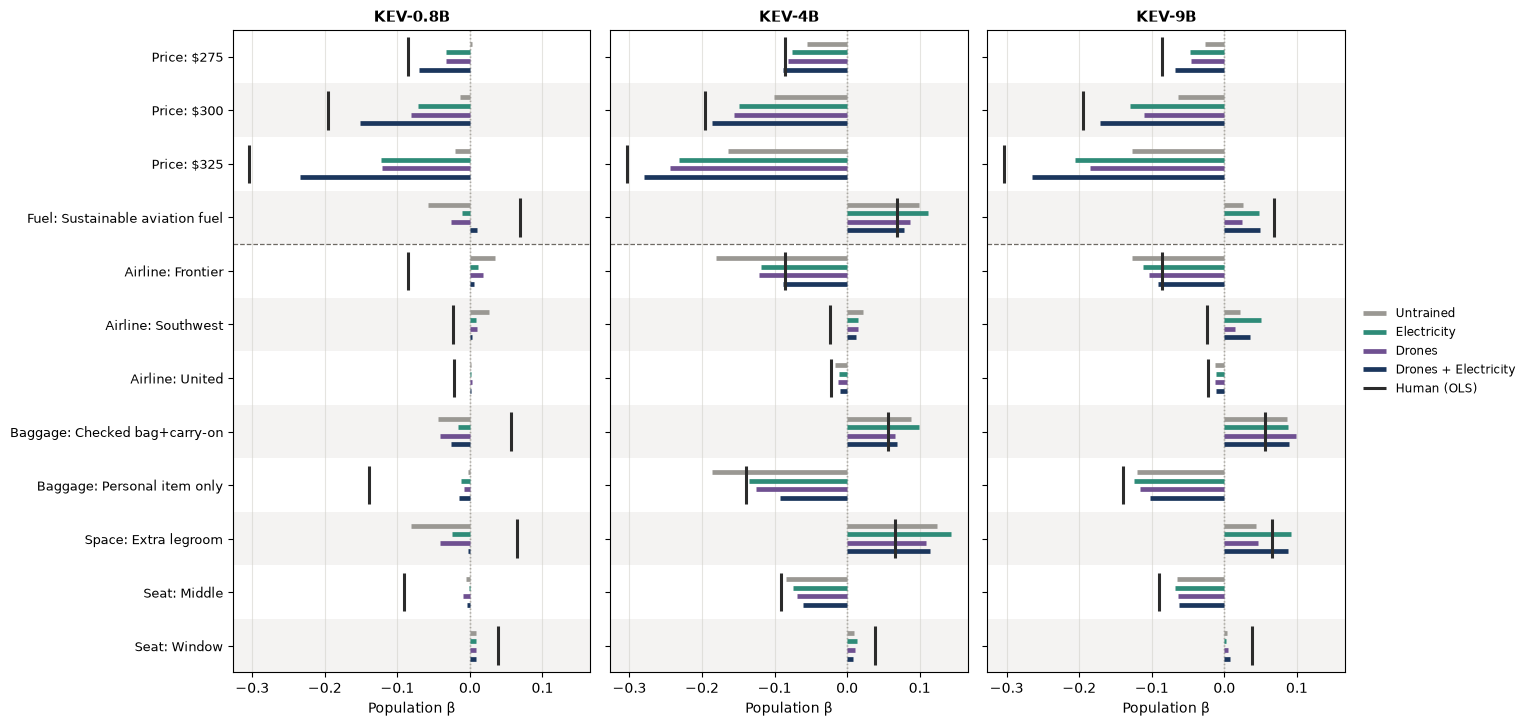

Note. Bars show each model's population β for each Flights † (Goldfarb et al., 2026) attribute level; the black vertical tick marks the human OLS slope on the same row. Price and sustainable aviation fuel (closest to Electricity's bill and renewables attributes) are listed first above the dashed divider. Exact values are in Table A3. † Flights is the validation set and selects each run's checkpoint (best.pt).


In [9]:
def load_kriner_betas(model_slug: str, slug: str, human_betas: pd.Series) -> pd.DataFrame:
    if slug == BASE_SLUG:
        return step0_kriner_betas_by_model[model_slug].loc[human_betas.index, ["human_pop_beta", "model_pop_beta"]]
    run_dir = find_run_dir(model_slug, slug)
    if not run_is_finished(run_dir):
        return pd.DataFrame({"human_pop_beta": human_betas, "model_pop_beta": np.nan})
    _, betas = load_paper_run(run_dir).best_validation["kriner2026"]
    if list(betas.index) != list(human_betas.index):
        raise ValueError(f"{model_slug}/{slug}: Flights terms {list(betas.index)} != {list(human_betas.index)}")
    return betas[["human_pop_beta", "model_pop_beta"]]


kriner_betas_by_model: dict[str, dict[str, pd.DataFrame]] = {}
for model_slug in MODEL_SLUGS:
    human_betas = step0_kriner_betas_by_model[model_slug]["human_pop_beta"]
    kriner_betas_by_model[model_slug] = {
        slug: load_kriner_betas(model_slug, slug, human_betas) for slug in ALL_SLUGS
    }

all_kriner_terms = list(kriner_betas_by_model[MODEL_SLUGS[0]][BASE_SLUG].index)
price_terms = [t for t in all_kriner_terms if t.startswith("Price:")]
fuel_terms = [t for t in all_kriner_terms if t.startswith("Fuel:")]
if not price_terms or not fuel_terms:
    raise ValueError(f"Expected Price and Fuel terms in Flights †: {all_kriner_terms}")
transferred_terms = price_terms + fuel_terms
other_terms = [t for t in all_kriner_terms if t not in transferred_terms]
kriner_terms = transferred_terms + other_terms
TRANSFERRED_DIVIDER_Y = len(transferred_terms) - 0.5
y_positions = np.arange(len(kriner_terms))

FLIGHTS_Y_OFFSETS = {
    "row1_base_untrained": -0.24,
    "row2b_wu_ce_oracle": -0.08,
    "row3_berke_ce_only": 0.08,
    "row5_full_berke_wu_ce_oracle": 0.24,
}
HUMAN_TICK_HALF_HEIGHT = 0.36

print_caption("Figure 2", "Flights † Population β by Attribute: Humans Versus Untrained and Fine-Tuned Models")
fig, axes = plt.subplots(1, len(MODEL_SLUGS), figsize=(3.8 * len(MODEL_SLUGS) + 4.0, 0.48 * len(kriner_terms) + 1.6), sharey=True, sharex=True)
for ax, model_slug in zip(axes, MODEL_SLUGS):
    ax.axvline(0.0, color=NEUTRALS["ref_line"], linewidth=1.0, linestyle=":", zorder=1)
    ax.axhline(TRANSFERRED_DIVIDER_Y, color=NEUTRALS["ref_line"], linestyle="--", linewidth=0.9, zorder=2)
    for y in y_positions:
        if y % 2 == 1:
            ax.axhspan(y - 0.5, y + 0.5, color=NEUTRALS["grid"], alpha=0.25, zorder=0, linewidth=0)

    for slug in ALL_SLUGS:
        betas = kriner_betas_by_model[model_slug][slug].loc[kriner_terms]
        model_values = betas["model_pop_beta"].to_numpy(dtype=float)
        y_shifted = y_positions + FLIGHTS_Y_OFFSETS[slug]
        ax.hlines(y_shifted, 0.0, model_values, color=STORY_COLORS[slug], linewidth=3.4, zorder=3, label=STORY_LABELS[slug])

    human_values = kriner_betas_by_model[model_slug][BASE_SLUG].loc[kriner_terms, "human_pop_beta"].to_numpy(dtype=float)
    ax.vlines(human_values, y_positions - HUMAN_TICK_HALF_HEIGHT, y_positions + HUMAN_TICK_HALF_HEIGHT, color=NEUTRALS["text"], linewidth=2.2, zorder=4, label="Human (OLS)")

    ax.set_title(MODEL_DISPLAY[model_slug], fontsize=11, fontweight="bold")
    ax.set_xlabel("Population β")
    ax.grid(axis="x", color=NEUTRALS["grid"], alpha=0.6)

axes[0].set_yticks(y_positions)
axes[0].set_yticklabels(kriner_terms, fontsize=9)
axes[0].set_ylim(-0.5, len(kriner_terms) - 0.5)
axes[0].invert_yaxis()
axes[-1].legend(fontsize=8.5, loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)
fig.tight_layout()
plt.show()
print_note(
    "Bars show each model's population β for each Flights † (Goldfarb et al., 2026) attribute level; the black vertical tick marks the human OLS slope on the same row. "
    "Price and sustainable aviation fuel (closest to Electricity's bill and renewables attributes) are listed first above the dashed divider. "
    "Exact values are in Table A3. † Flights is the validation set and selects each run's checkpoint (best.pt)."
)

---
### Held-Out Attribute Transfer: `Consumer rights` (Table 2, Figure 3)

Table 2
Consumer Rights Population β MSE (×10³) by Attribute Group and Product


Note. Held-out Consumer rights benchmark (Kantorowicz-Reznichenko et al., 2026; 38 AMCEs across 19 laptop and 19 laundry-machine slopes). Values are population β MSE ×10³, with percentage change versus the untrained model in parentheses; lower is better. Bold marks the lowest trained value per model and column when it improves on Untrained. Price (4) = laptop and laundry price slopes; Brand (6) = brand dummies; Product specs (12) = RAM, storage, processor, depth, noise, and load capacity; Contractual rights (16) = warranty, privacy, liability, and conflict resolution.
Figure 3
Consumer Rights Population β MSE by Attribute Group: Price Versus Non-Price Attributes


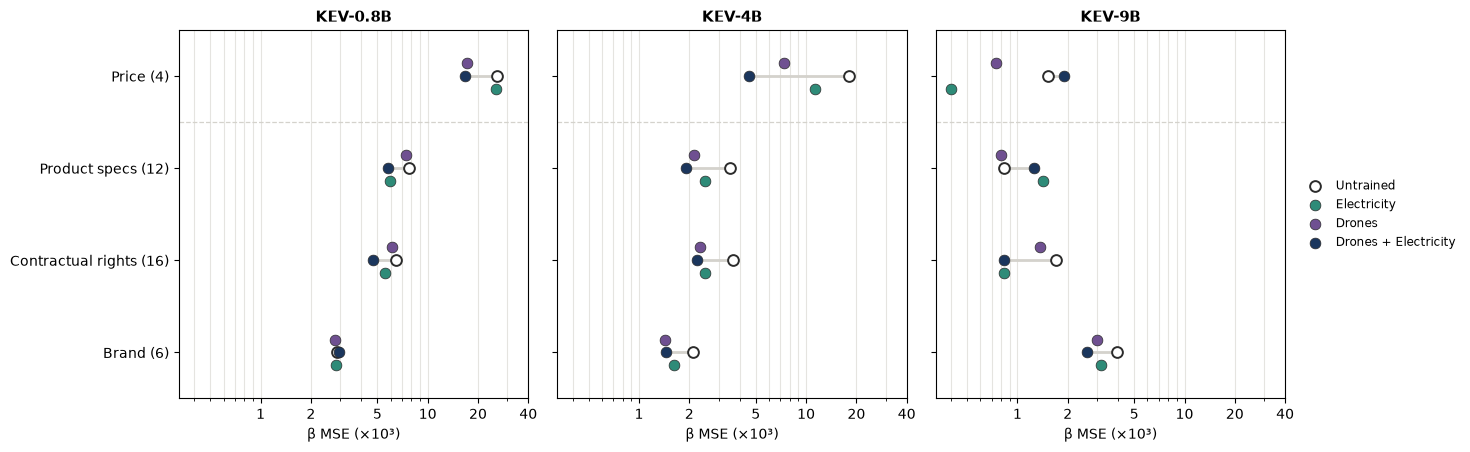

Note. Open circles are the untrained model; filled circles are fine-tuned runs on the held-out Consumer rights test set (Kantorowicz-Reznichenko et al., 2026). Population β MSE ×10³ on a shared log scale; lower is better. The grey bar joins Untrained to Drones + Electricity. The dashed horizontal line separates Price (above) from non-price attribute groups (below).


In [10]:
K26_ATTR_GROUPS = (
    ("price", "Price (4)"),
    ("brand", "Brand (6)"),
    ("specs", "Product specs (12)"),
    ("rights", "Contractual rights (16)"),
)
K26_BREAKDOWN_COLUMNS = (
    ("all", "All (38)"),
    ("price", "Price (4)"),
    ("brand", "Brand (6)"),
    ("specs", "Product specs (12)"),
    ("rights", "Contractual rights (16)"),
    ("computers", "Laptops (19)"),
    ("laundry", "Laundry (19)"),
)
K26_SPECS_ATTRS = {"RAM", "Storage", "Processor", "Depth", "Noise", "Load capacity"}
K26_RIGHTS_ATTRS = {"Warranty", "Privacy", "Liability", "Conflict resolution"}


def kantorowicz_attr_group(term: str) -> str:
    _, rest = term.split(" | ", 1)
    attr = rest.split(":", 1)[0]
    if attr == "Price":
        return "price"
    if attr == "Brand":
        return "brand"
    if attr in K26_SPECS_ATTRS:
        return "specs"
    if attr in K26_RIGHTS_ATTRS:
        return "rights"
    raise ValueError(f"Unrecognized Consumer rights attribute in term {term!r}")


def kantorowicz_breakdown_metrics(beta_df: pd.DataFrame) -> dict[str, float]:
    sq_err = (beta_df["model_pop_beta"] - beta_df["human_pop_beta"]).pow(2)
    groups = pd.Series([kantorowicz_attr_group(t) for t in beta_df.index], index=beta_df.index)
    out = {"all": float(sq_err.mean())}
    for g_key, _ in K26_ATTR_GROUPS:
        mask = groups == g_key
        if not mask.any():
            raise ValueError(f"No terms matched Consumer rights group {g_key!r}")
        out[g_key] = float(sq_err.loc[mask].mean())
    for prod_key, model_name in (("computers", "kantorowicz2026/computers"), ("laundry", "kantorowicz2026/laundry")):
        mask = beta_df["model"] == model_name
        if not mask.any():
            raise ValueError(f"No terms matched Consumer rights model {model_name!r}")
        out[prod_key] = float(sq_err.loc[mask].mean())
    return out


k26_breakdown_frames = []
for model_slug in MODEL_SLUGS:
    betas_by_slug = kantorowicz_betas_by_model[model_slug]
    rows = []
    for slug in ALL_SLUGS:
        if slug in betas_by_slug:
            metrics = kantorowicz_breakdown_metrics(betas_by_slug[slug])
        else:
            metrics = {col_key: np.nan for col_key, _ in K26_BREAKDOWN_COLUMNS}
        rows.append({col_label: metrics[col_key] for col_key, col_label in K26_BREAKDOWN_COLUMNS})
    frame = pd.DataFrame(rows)
    frame.index = pd.MultiIndex.from_tuples(
        [(MODEL_DISPLAY[model_slug], slug) for slug in ALL_SLUGS],
        names=["Model", "Trained on"],
    )
    k26_breakdown_frames.append(frame)

k26_breakdown_values = pd.concat(k26_breakdown_frames)
k26_breakdown_text = pd.DataFrame("", index=k26_breakdown_values.index, columns=k26_breakdown_values.columns)
for model_name, slug in k26_breakdown_values.index:
    for col in k26_breakdown_values.columns:
        val = float(k26_breakdown_values.loc[(model_name, slug), col])
        base_val = float(k26_breakdown_values.loc[(model_name, BASE_SLUG), col])
        k26_breakdown_text.loc[(model_name, slug), col] = format_mse_cell(val, base_val, slug)

k26_breakdown_css = relabel_rows(best_cell_css(k26_breakdown_values))
print_caption("Table 2", "Consumer Rights Population β MSE (×10³) by Attribute Group and Product")
display(relabel_rows(k26_breakdown_text).style.apply(lambda _df: k26_breakdown_css, axis=None))
print_note(
    "Held-out Consumer rights benchmark (Kantorowicz-Reznichenko et al., 2026; 38 AMCEs across 19 laptop and 19 laundry-machine slopes). "
    "Values are population β MSE ×10³, with percentage change versus the untrained model in parentheses; lower is better. "
    "Bold marks the lowest trained value per model and column when it improves on Untrained. "
    "Price (4) = laptop and laundry price slopes; Brand (6) = brand dummies; Product specs (12) = RAM, storage, processor, depth, noise, and load capacity; "
    "Contractual rights (16) = warranty, privacy, liability, and conflict resolution."
)

ATTR_Y_OFFSETS = {
    "row1_base_untrained": 0.0,
    "row2b_wu_ce_oracle": 0.14,
    "row3_berke_ce_only": -0.14,
    "row5_full_berke_wu_ce_oracle": 0.0,
}
K26_PLOT_GROUPS = (
    "Price (4)",
    "Product specs (12)",
    "Contractual rights (16)",
    "Brand (6)",
)

print_caption("Figure 3", "Consumer Rights Population β MSE by Attribute Group: Price Versus Non-Price Attributes")
fig, axes = plt.subplots(
    1,
    len(MODEL_SLUGS),
    figsize=(3.6 * len(MODEL_SLUGS) + 4.0, 0.78 * len(K26_PLOT_GROUPS) + 1.5),
    sharex=True,
    sharey=True,
    squeeze=False,
)
axes = axes[0]
k26_y_positions = np.arange(len(K26_PLOT_GROUPS))
k26_x_ticks = (1, 2, 5, 10, 20, 40)

for ax, model_slug in zip(axes, MODEL_SLUGS):
    model_block = k26_breakdown_values.xs(MODEL_DISPLAY[model_slug], level="Model")
    ax.axhline(0.5, color=NEUTRALS["grid"], linestyle="--", linewidth=0.9, zorder=0)
    for y, col_label in zip(k26_y_positions, K26_PLOT_GROUPS):
        base_val = float(model_block.loc[BASE_SLUG, col_label]) * MSE_SCALE
        end_val = float(model_block.loc["row5_full_berke_wu_ce_oracle", col_label]) * MSE_SCALE
        if not np.isnan(base_val) and not np.isnan(end_val):
            ax.plot([end_val, base_val], [y, y], color=NEUTRALS["grid"], linewidth=2.0, zorder=1)
    for slug in ALL_SLUGS:
        vals = [float(model_block.loc[slug, col_label]) * MSE_SCALE for col_label in K26_PLOT_GROUPS]
        y_shifted = k26_y_positions + ATTR_Y_OFFSETS[slug]
        if slug == BASE_SLUG:
            ax.scatter(vals, y_shifted, s=60, facecolors="white", edgecolors=NEUTRALS["text"], linewidths=1.4, zorder=3, label=STORY_LABELS[slug])
        else:
            ax.scatter(vals, y_shifted, s=60, color=STORY_COLORS[slug], edgecolors=NEUTRALS["text"], linewidths=0.5, zorder=3, label=STORY_LABELS[slug])
    ax.set_xscale("log")
    ax.set_xticks(k26_x_ticks)
    ax.set_xticklabels([f"{t:g}" for t in k26_x_ticks])
    ax.xaxis.set_minor_formatter(NullFormatter())
    ax.set_title(MODEL_DISPLAY[model_slug], fontsize=11, fontweight="bold")
    ax.set_xlabel("β MSE (×10³)")
    ax.grid(axis="x", color=NEUTRALS["grid"], alpha=0.6, which="both")

axes[0].set_yticks(k26_y_positions)
axes[0].set_yticklabels(K26_PLOT_GROUPS)
axes[0].set_ylim(-0.5, len(K26_PLOT_GROUPS) - 0.5)
axes[0].invert_yaxis()
axes[-1].legend(fontsize=8.5, loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)
fig.tight_layout()
plt.show()
print_note(
    "Open circles are the untrained model; filled circles are fine-tuned runs on the held-out Consumer rights test set (Kantorowicz-Reznichenko et al., 2026). "
    "Population β MSE ×10³ on a shared log scale; lower is better. The grey bar joins Untrained to Drones + Electricity. "
    "The dashed horizontal line separates Price (above) from non-price attribute groups (below)."
)

---
### Held-Out Attribute Transfer: `AI & offshoring` (Table 3, Figure 4)

Table 3
AI & Offshoring Population β MSE (×10³) by Attribute Group and Country × Arm


Note. Held-out AI & offshoring benchmark (Magistro et al., 2025; 32 AMCEs across 4 country × arm regressions of 8 slopes each). Values are population β MSE ×10³, with percentage change versus the untrained model in parentheses; lower is better. Bold marks the lowest trained value per model and column when it improves on Untrained. NaN = held-out AI & offshoring evaluation not finished yet.
Figure 4
AI & Offshoring Population β MSE by Attribute Group: Price Versus Job-Change Attributes


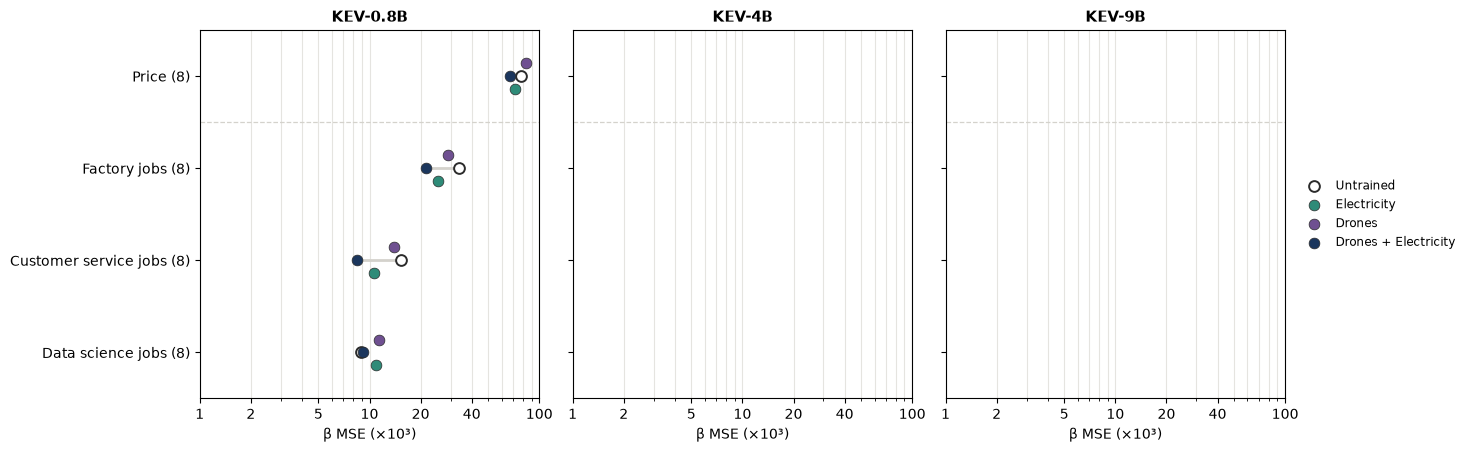

Note. Open circles are the untrained model; filled circles are fine-tuned runs on the held-out AI & offshoring test set (Magistro et al., 2025). Population β MSE ×10³ on a shared log scale; lower is better. The grey bar joins Untrained to Drones + Electricity. The dashed horizontal line separates Price (above) from job-change attribute groups (below). Missing points: held-out evaluations not finished yet.


In [11]:
M25_ATTR_GROUPS = (
    ("price", "Price (8)"),
    ("factory", "Factory jobs (8)"),
    ("service", "Customer service jobs (8)"),
    ("datasci", "Data science jobs (8)"),
)
M25_BREAKDOWN_COLUMNS = (
    ("all", "All (32)"),
    ("price", "Price (8)"),
    ("factory", "Factory jobs (8)"),
    ("service", "Customer service jobs (8)"),
    ("datasci", "Data science jobs (8)"),
    ("us_ai", "US AI (8)"),
    ("us_offshoring", "US Offshoring (8)"),
    ("ca_ai", "CA AI (8)"),
    ("ca_offshoring", "CA Offshoring (8)"),
)


def magistro_attr_group(term: str) -> str:
    _, rest = term.split(" | ", 1)
    attr = rest.split(":", 1)[0]
    if attr == "Price":
        return "price"
    if attr == "Factory jobs":
        return "factory"
    if attr == "Customer service jobs":
        return "service"
    if attr == "Data science jobs":
        return "datasci"
    raise ValueError(f"Unrecognized AI & offshoring attribute in term {term!r}")


def magistro_breakdown_metrics(beta_df: pd.DataFrame) -> dict[str, float]:
    sq_err = (beta_df["model_pop_beta"] - beta_df["human_pop_beta"]).pow(2)
    groups = pd.Series([magistro_attr_group(t) for t in beta_df.index], index=beta_df.index)
    out = {"all": float(sq_err.mean())}
    for g_key, _ in M25_ATTR_GROUPS:
        mask = groups == g_key
        if not mask.any():
            raise ValueError(f"No terms matched AI & offshoring group {g_key!r}")
        out[g_key] = float(sq_err.loc[mask].mean())
    for sub_key in ("us_ai", "us_offshoring", "ca_ai", "ca_offshoring"):
        model_name = f"magistro2025/{sub_key}"
        mask = beta_df["model"] == model_name
        if not mask.any():
            raise ValueError(f"No terms matched AI & offshoring model {model_name!r}")
        out[sub_key] = float(sq_err.loc[mask].mean())
    return out


m25_breakdown_frames = []
for model_slug in MODEL_SLUGS:
    betas_by_slug = magistro_betas_by_model[model_slug]
    rows = []
    for slug in ALL_SLUGS:
        if slug in betas_by_slug:
            metrics = magistro_breakdown_metrics(betas_by_slug[slug])
        else:
            metrics = {col_key: np.nan for col_key, _ in M25_BREAKDOWN_COLUMNS}
        rows.append({col_label: metrics[col_key] for col_key, col_label in M25_BREAKDOWN_COLUMNS})
    frame = pd.DataFrame(rows)
    frame.index = pd.MultiIndex.from_tuples(
        [(MODEL_DISPLAY[model_slug], slug) for slug in ALL_SLUGS],
        names=["Model", "Trained on"],
    )
    m25_breakdown_frames.append(frame)

m25_breakdown_values = pd.concat(m25_breakdown_frames)
m25_breakdown_text = pd.DataFrame("", index=m25_breakdown_values.index, columns=m25_breakdown_values.columns)
for model_name, slug in m25_breakdown_values.index:
    for col in m25_breakdown_values.columns:
        val = float(m25_breakdown_values.loc[(model_name, slug), col])
        base_val = float(m25_breakdown_values.loc[(model_name, BASE_SLUG), col])
        m25_breakdown_text.loc[(model_name, slug), col] = format_mse_cell(val, base_val, slug)

m25_breakdown_css = relabel_rows(best_cell_css(m25_breakdown_values))
print_caption("Table 3", "AI & Offshoring Population β MSE (×10³) by Attribute Group and Country × Arm")
display(relabel_rows(m25_breakdown_text).style.apply(lambda _df: m25_breakdown_css, axis=None))
print_note(
    "Held-out AI & offshoring benchmark (Magistro et al., 2025; 32 AMCEs across 4 country × arm regressions of 8 slopes each). "
    "Values are population β MSE ×10³, with percentage change versus the untrained model in parentheses; lower is better. "
    "Bold marks the lowest trained value per model and column when it improves on Untrained. "
    "NaN = held-out AI & offshoring evaluation not finished yet."
)

M25_PLOT_GROUPS = (
    "Price (8)",
    "Factory jobs (8)",
    "Customer service jobs (8)",
    "Data science jobs (8)",
)

if not m25_breakdown_values[list(M25_PLOT_GROUPS)].notna().any().any():
    print("Figure 4 pending: run 04-test-best-*.ipynb to populate magistro2025 in test_best/.")
else:
    print_caption("Figure 4", "AI & Offshoring Population β MSE by Attribute Group: Price Versus Job-Change Attributes")
    fig, axes = plt.subplots(
        1,
        len(MODEL_SLUGS),
        figsize=(3.6 * len(MODEL_SLUGS) + 4.0, 0.78 * len(M25_PLOT_GROUPS) + 1.5),
        sharex=True,
        sharey=True,
        squeeze=False,
    )
    axes = axes[0]
    m25_y_positions = np.arange(len(M25_PLOT_GROUPS))
    m25_x_ticks = (1, 2, 5, 10, 20, 40, 100)

    for ax, model_slug in zip(axes, MODEL_SLUGS):
        model_block = m25_breakdown_values.xs(MODEL_DISPLAY[model_slug], level="Model")
        ax.axhline(0.5, color=NEUTRALS["grid"], linestyle="--", linewidth=0.9, zorder=0)
        for y, col_label in zip(m25_y_positions, M25_PLOT_GROUPS):
            base_val = float(model_block.loc[BASE_SLUG, col_label]) * MSE_SCALE
            end_val = float(model_block.loc["row5_full_berke_wu_ce_oracle", col_label]) * MSE_SCALE
            if not np.isnan(base_val) and not np.isnan(end_val):
                ax.plot([end_val, base_val], [y, y], color=NEUTRALS["grid"], linewidth=2.0, zorder=1)
        for slug in ALL_SLUGS:
            vals = [float(model_block.loc[slug, col_label]) * MSE_SCALE for col_label in M25_PLOT_GROUPS]
            y_shifted = m25_y_positions + ATTR_Y_OFFSETS[slug]
            if slug == BASE_SLUG:
                ax.scatter(vals, y_shifted, s=60, facecolors="white", edgecolors=NEUTRALS["text"], linewidths=1.4, zorder=3, label=STORY_LABELS[slug])
            else:
                ax.scatter(vals, y_shifted, s=60, color=STORY_COLORS[slug], edgecolors=NEUTRALS["text"], linewidths=0.5, zorder=3, label=STORY_LABELS[slug])
        ax.set_xscale("log")
        ax.set_xticks(m25_x_ticks)
        ax.set_xticklabels([f"{t:g}" for t in m25_x_ticks])
        ax.xaxis.set_minor_formatter(NullFormatter())
        ax.set_title(MODEL_DISPLAY[model_slug], fontsize=11, fontweight="bold")
        ax.set_xlabel("β MSE (×10³)")
        ax.grid(axis="x", color=NEUTRALS["grid"], alpha=0.6, which="both")

    axes[0].set_yticks(m25_y_positions)
    axes[0].set_yticklabels(M25_PLOT_GROUPS)
    axes[0].set_ylim(-0.5, len(M25_PLOT_GROUPS) - 0.5)
    axes[0].invert_yaxis()
    axes[-1].legend(fontsize=8.5, loc="center left", bbox_to_anchor=(1.02, 0.5), frameon=False)
    fig.tight_layout()
    plt.show()
    print_note(
        "Open circles are the untrained model; filled circles are fine-tuned runs on the held-out AI & offshoring test set (Magistro et al., 2025). "
        "Population β MSE ×10³ on a shared log scale; lower is better. The grey bar joins Untrained to Drones + Electricity. "
        "The dashed horizontal line separates Price (above) from job-change attribute groups (below). Missing points: held-out evaluations not finished yet."
    )

---
## Appendix — Choice KL for Table 1 (Table A1)

In [12]:
table_a1_df = relabel_rows(build_metric_table(MODEL_SLUGS, ALL_SLUGS, "kl", STORY_COLUMNS).round(3))
print_caption("Table A1", "Choice KL Across Benchmarks After Microdata Fine-Tuning")
display(table_a1_df)
print_note(
    "Choice KL = mean −log probability the model assigns to the option each respondent chose (the KL divergence from each observed choice); lower is better. "
    f"{ROLES_NOTE} NaN = held-out test evaluation not finished yet."
)

Table A1
Choice KL Across Benchmarks After Microdata Fine-Tuning


Food labels  Vaccines  Consumer rights  AI & offshoring  Flights †
Model    Trained on                                                                              
KEV-0.8B Untrained                   1.059     1.185            1.418            2.283      1.086
         Electricity                 0.915     1.082            0.821            1.689      0.693
         Drones                      0.953     1.105            0.806            1.630      0.709
         Drones + Electricity        0.879     1.067            0.695            1.558      0.647
KEV-4B   Untrained                   1.100     1.525            0.779              NaN      0.811
         Electricity                 0.887     1.120            0.650              NaN      0.625
         Drones                      0.959     1.195            0.663              NaN      0.623
         Drones + Electricity        0.854     1.046            0.629              NaN      0.588
KEV-9B   Untrained                   1.238     1.422            0.804              NaN      0.833
         Electricity                 0.972     1.203            0.694              NaN      0.647
         Drones                      0.963     1.165            0.674              NaN      0.646
         Drones + Electricity        0.808     1.100            0.665              NaN      0.604

Note. Choice KL = mean −log probability the model assigns to the option each respondent chose (the KL divergence from each observed choice); lower is better. Food labels (Grummon et al., 2025), Vaccines (Kreps et al., 2020), Consumer rights (Kantorowicz-Reznichenko et al., 2026), and AI & offshoring (Magistro et al., 2025) are held-out test sets; † Flights (Goldfarb et al., 2026) is the validation set and selects each run's checkpoint (best.pt). NaN = held-out test evaluation not finished yet.


---
## Appendix — `Vaccines` Slopes by Attribute (Table A2)

In [13]:
for model_index, model_slug in enumerate(MODEL_SLUGS):
    betas_by_slug = covid_betas_by_model[model_slug]
    columns = {"Human (OLS)": betas_by_slug[BASE_SLUG]["human_pop_beta"]}
    for slug in ALL_SLUGS:
        if slug in betas_by_slug:
            columns[STORY_LABELS[slug]] = betas_by_slug[slug]["model_pop_beta"]
        else:
            columns[STORY_LABELS[slug]] = pd.Series(np.nan, index=columns["Human (OLS)"].index)
    kreps_term_df = pd.DataFrame(columns)
    kreps_term_df.index.name = "Vaccine attribute level"
    squared_error = kreps_term_df.sub(kreps_term_df["Human (OLS)"], axis=0).pow(2)
    kreps_term_df.loc["β MSE vs. human"] = squared_error.mean()
    print_caption(f"Table A2{TABLE_LETTERS[model_index]}", f"Vaccines Population β by Attribute: {MODEL_DISPLAY[model_slug]}")
    display(kreps_term_df.round(4))
    print_note("Vaccines (Kreps et al., 2020) is a held-out test set. Human (OLS) = slope fitted on respondents' choices. The last row is β MSE versus human.")

Table A2a
Vaccines Population β by Attribute: KEV-0.8B


,Human (OLS),Untrained,Electricity,Drones,Drones + Electricity
Vaccine attribute level,,,,,
Efficacy: 70% vs 50%,0.0744,0.0420,0.0539,0.0363,0.0556
Efficacy: 90% vs 50%,0.1641,0.0650,0.0957,0.0619,0.1035
Duration: 5y vs 1y,0.0541,0.0169,0.0278,0.0093,0.0230
Severe side effects: 1/1M vs 1/10k,0.0653,0.0094,0.0195,0.0133,0.0240
Mild side effects: 1/30 vs 1/10,0.0125,-0.0005,-0.0043,-0.0065,-0.0090
FDA: EUA vs Full approval,-0.0287,0.0340,0.0193,0.0243,0.0174
Origin: UK vs US,-0.0380,-0.0253,-0.0255,-0.0292,-0.0297
Origin: China vs US,-0.1308,0.0279,0.0068,0.0068,-0.0037
Endorsed: Biden vs Trump,0.0181,0.1092,0.0910,0.0592,0.0628


Note. Vaccines (Kreps et al., 2020) is a held-out test set. Human (OLS) = slope fitted on respondents' choices. The last row is β MSE versus human.
Table A2b
Vaccines Population β by Attribute: KEV-4B


,Human (OLS),Untrained,Electricity,Drones,Drones + Electricity
Vaccine attribute level,,,,,
Efficacy: 70% vs 50%,0.0744,0.1253,0.1130,0.1267,0.1086
Efficacy: 90% vs 50%,0.1641,0.2377,0.2148,0.2446,0.2113
Duration: 5y vs 1y,0.0541,0.0046,0.0325,0.0183,0.0383
Severe side effects: 1/1M vs 1/10k,0.0653,0.0235,0.0324,0.0376,0.0450
Mild side effects: 1/30 vs 1/10,0.0125,0.0080,0.0177,0.0094,0.0181
FDA: EUA vs Full approval,-0.0287,-0.0678,-0.0477,-0.0621,-0.0385
Origin: UK vs US,-0.0380,-0.0812,-0.0553,-0.0891,-0.0529
Origin: China vs US,-0.1308,-0.1969,-0.1214,-0.1910,-0.1143
Endorsed: Biden vs Trump,0.0181,0.0503,-0.0007,0.0569,0.0463


Note. Vaccines (Kreps et al., 2020) is a held-out test set. Human (OLS) = slope fitted on respondents' choices. The last row is β MSE versus human.
Table A2c
Vaccines Population β by Attribute: KEV-9B


,Human (OLS),Untrained,Electricity,Drones,Drones + Electricity
Vaccine attribute level,,,,,
Efficacy: 70% vs 50%,0.0744,0.2110,0.1715,0.1865,0.1541
Efficacy: 90% vs 50%,0.1641,0.3693,0.3165,0.3322,0.2895
Duration: 5y vs 1y,0.0541,0.0253,0.0335,0.0372,0.0459
Severe side effects: 1/1M vs 1/10k,0.0653,0.0502,0.0522,0.0549,0.0542
Mild side effects: 1/30 vs 1/10,0.0125,0.0156,0.0190,0.0148,0.0201
FDA: EUA vs Full approval,-0.0287,-0.0077,-0.0144,-0.0079,-0.0128
Origin: UK vs US,-0.0380,-0.0717,-0.0589,-0.0563,-0.0506
Origin: China vs US,-0.1308,-0.2047,-0.1656,-0.1598,-0.1432
Endorsed: Biden vs Trump,0.0181,0.1179,0.0524,0.1089,0.0396


Note. Vaccines (Kreps et al., 2020) is a held-out test set. Human (OLS) = slope fitted on respondents' choices. The last row is β MSE versus human.


---
## Appendix — `Flights †` Slopes by Attribute (Table A3)

In [14]:
for model_index, model_slug in enumerate(MODEL_SLUGS):
    betas_by_slug = kriner_betas_by_model[model_slug]
    columns = {"Human (OLS)": betas_by_slug[BASE_SLUG].loc[kriner_terms, "human_pop_beta"]}
    for slug in ALL_SLUGS:
        columns[STORY_LABELS[slug]] = betas_by_slug[slug].loc[kriner_terms, "model_pop_beta"]
    kriner_term_df = pd.DataFrame(columns)
    kriner_term_df.index.name = "Flight attribute level"
    squared_error = kriner_term_df.sub(kriner_term_df["Human (OLS)"], axis=0).pow(2)
    kriner_term_df.loc["β MSE vs. human"] = squared_error.mean()
    print_caption(f"Table A3{TABLE_LETTERS[model_index]}", f"Flights † Population β by Attribute: {MODEL_DISPLAY[model_slug]}")
    display(kriner_term_df.round(4))
    print_note("Values behind Figure 2 (Price and sustainable aviation fuel listed first). Human (OLS) = slope fitted on respondents' choices. † Flights (Goldfarb et al., 2026) is the validation set and selects each run's checkpoint (best.pt).")

Table A3a
Flights † Population β by Attribute: KEV-0.8B


,Human (OLS),Untrained,Electricity,Drones,Drones + Electricity
Flight attribute level,,,,,
Price: $275,-0.0853,0.0032,-0.0328,-0.0327,-0.0701
Price: $300,-0.1953,-0.0134,-0.0718,-0.0816,-0.1519
Price: $325,-0.3040,-0.0200,-0.1221,-0.1210,-0.2335
Fuel: Sustainable aviation fuel,0.0691,-0.0573,-0.0110,-0.0258,0.0096
Airline: Frontier,-0.0854,0.0344,0.0110,0.0175,0.0055
Airline: Southwest,-0.0238,0.0267,0.0081,0.0103,0.0026
Airline: United,-0.0220,0.0011,0.0009,0.0029,0.0021
Baggage: Checked bag+carry-on,0.0561,-0.0433,-0.0160,-0.0408,-0.0257
Baggage: Personal item only,-0.1393,-0.0029,-0.0116,-0.0084,-0.0145


Note. Values behind Figure 2 (Price and sustainable aviation fuel listed first). Human (OLS) = slope fitted on respondents' choices. † Flights (Goldfarb et al., 2026) is the validation set and selects each run's checkpoint (best.pt).
Table A3b
Flights † Population β by Attribute: KEV-4B


,Human (OLS),Untrained,Electricity,Drones,Drones + Electricity
Flight attribute level,,,,,
Price: $275,-0.0853,-0.0553,-0.0763,-0.0821,-0.0884
Price: $300,-0.1953,-0.1012,-0.1494,-0.1552,-0.1864
Price: $325,-0.3040,-0.1636,-0.2321,-0.2441,-0.2802
Fuel: Sustainable aviation fuel,0.0691,0.0996,0.1108,0.0873,0.0788
Airline: Frontier,-0.0854,-0.1803,-0.1185,-0.1218,-0.0886
Airline: Southwest,-0.0238,0.0224,0.0145,0.0153,0.0116
Airline: United,-0.0220,-0.0163,-0.0109,-0.0121,-0.0100
Baggage: Checked bag+carry-on,0.0561,0.0875,0.0989,0.0658,0.0687
Baggage: Personal item only,-0.1393,-0.1864,-0.1347,-0.1259,-0.0919


Note. Values behind Figure 2 (Price and sustainable aviation fuel listed first). Human (OLS) = slope fitted on respondents' choices. † Flights (Goldfarb et al., 2026) is the validation set and selects each run's checkpoint (best.pt).
Table A3c
Flights † Population β by Attribute: KEV-9B


,Human (OLS),Untrained,Electricity,Drones,Drones + Electricity
Flight attribute level,,,,,
Price: $275,-0.0853,-0.0265,-0.0477,-0.0453,-0.0685
Price: $300,-0.1953,-0.0639,-0.1295,-0.1108,-0.1716
Price: $325,-0.3040,-0.1271,-0.2056,-0.1847,-0.2645
Fuel: Sustainable aviation fuel,0.0691,0.0255,0.0474,0.0239,0.0486
Airline: Frontier,-0.0854,-0.1273,-0.1127,-0.1044,-0.0918
Airline: Southwest,-0.0238,0.0212,0.0512,0.0152,0.0360
Airline: United,-0.0220,-0.0135,-0.0115,-0.0132,-0.0118
Baggage: Checked bag+carry-on,0.0561,0.0863,0.0878,0.0986,0.0885
Baggage: Personal item only,-0.1393,-0.1202,-0.1244,-0.1167,-0.1031


Note. Values behind Figure 2 (Price and sustainable aviation fuel listed first). Human (OLS) = slope fitted on respondents' choices. † Flights (Goldfarb et al., 2026) is the validation set and selects each run's checkpoint (best.pt).


---
## Appendix — `Consumer rights` Slopes by Attribute (Table A4)

In [15]:
k26_human_reference = None
for model_slug in MODEL_SLUGS:
    if BASE_SLUG in kantorowicz_betas_by_model[model_slug]:
        ref_df = kantorowicz_betas_by_model[model_slug][BASE_SLUG][["model", "human_pop_beta"]]
        if k26_human_reference is None:
            k26_human_reference = ref_df
        else:
            if list(ref_df.index) != list(k26_human_reference.index):
                raise ValueError(f"{model_slug}: Consumer rights term index mismatch")
            max_diff = float((ref_df["human_pop_beta"] - k26_human_reference["human_pop_beta"]).abs().max())
            if max_diff > 1e-12:
                raise ValueError(f"{model_slug}: Consumer rights human_pop_beta mismatch (max_diff={max_diff})")
if k26_human_reference is None:
    raise FileNotFoundError("No model has kantorowicz2026 in test_best/ yet")

k26_price_mask = pd.Series(
    [kantorowicz_attr_group(t) == "price" for t in k26_human_reference.index],
    index=k26_human_reference.index,
)

for model_index, model_slug in enumerate(MODEL_SLUGS):
    betas_by_slug = kantorowicz_betas_by_model[model_slug]
    columns = {"Human (OLS)": k26_human_reference["human_pop_beta"]}
    for slug in ALL_SLUGS:
        if slug in betas_by_slug:
            columns[STORY_LABELS[slug]] = betas_by_slug[slug].loc[k26_human_reference.index, "model_pop_beta"]
        else:
            columns[STORY_LABELS[slug]] = pd.Series(np.nan, index=k26_human_reference.index)
    k26_term_df = pd.DataFrame(columns)
    k26_term_df.index.name = "Consumer rights attribute level"
    squared_error = k26_term_df.sub(k26_term_df["Human (OLS)"], axis=0).pow(2)
    k26_term_df.loc["Price β MSE vs. human (4)"] = squared_error.loc[k26_price_mask].mean()
    k26_term_df.loc["Non-price β MSE vs. human (34)"] = squared_error.loc[~k26_price_mask].mean()
    k26_term_df.loc["Overall β MSE vs. human (38)"] = squared_error.mean()
    print_caption(f"Table A4{TABLE_LETTERS[model_index]}", f"Consumer Rights Population β by Attribute: {MODEL_DISPLAY[model_slug]}")
    display(k26_term_df.round(4))
    print_note(
        "Consumer rights (Kantorowicz-Reznichenko et al., 2026) is a held-out test set spanning 19 laptop and 19 laundry-machine AMCEs (38 total). "
        "Human (OLS) = slope fitted on respondents' choices. Summary rows report Price (4), Non-price (34), and Overall (38) β MSE versus human."
    )

Table A4a
Consumer Rights Population β by Attribute: KEV-0.8B


,Human (OLS),Untrained,Electricity,Drones,Drones + Electricity
Consumer rights attribute level,,,,,
Computers | Price: $1250 vs $2000,0.0970,0.0032,-0.0060,0.0068,0.0005
Computers | Price: $500 vs $2000,0.2200,0.0113,-0.0002,0.0399,0.0258
Computers | Brand: Apple MacBook vs Medion,0.0315,-0.0116,-0.0024,0.0009,0.0138
Computers | Brand: Lenovo vs Medion,0.0462,-0.0063,-0.0014,-0.0027,0.0016
Computers | Brand: HP vs Medion,0.0799,-0.0009,0.0025,0.0008,0.0014
Computers | RAM: 10 GB vs 4 GB,0.0922,-0.0005,0.0152,0.0026,0.0176
Computers | RAM: 16 GB vs 4 GB,0.1472,0.0081,0.0356,0.0110,0.0364
Computers | Storage: 256 GB vs 128 GB,0.0631,0.0004,0.0025,-0.0004,0.0023
Computers | Storage: 512 GB vs 128 GB,0.1186,-0.0088,0.0054,-0.0043,0.0070


Note. Consumer rights (Kantorowicz-Reznichenko et al., 2026) is a held-out test set spanning 19 laptop and 19 laundry-machine AMCEs (38 total). Human (OLS) = slope fitted on respondents' choices. Summary rows report Price (4), Non-price (34), and Overall (38) β MSE versus human.
Table A4b
Consumer Rights Population β by Attribute: KEV-4B


,Human (OLS),Untrained,Electricity,Drones,Drones + Electricity
Consumer rights attribute level,,,,,
Computers | Price: $1250 vs $2000,0.0970,0.0367,0.0575,0.0629,0.0791
Computers | Price: $500 vs $2000,0.2200,0.0265,0.0756,0.0948,0.1278
Computers | Brand: Apple MacBook vs Medion,0.0315,-0.0226,0.0109,0.0063,0.0198
Computers | Brand: Lenovo vs Medion,0.0462,0.0128,0.0173,0.0213,0.0188
Computers | Brand: HP vs Medion,0.0799,0.0118,0.0182,0.0208,0.0188
Computers | RAM: 10 GB vs 4 GB,0.0922,0.0121,0.0371,0.0351,0.0458
Computers | RAM: 16 GB vs 4 GB,0.1472,0.0454,0.0744,0.0711,0.0853
Computers | Storage: 256 GB vs 128 GB,0.0631,0.0310,0.0363,0.0377,0.0395
Computers | Storage: 512 GB vs 128 GB,0.1186,0.0458,0.0632,0.0660,0.0731


Note. Consumer rights (Kantorowicz-Reznichenko et al., 2026) is a held-out test set spanning 19 laptop and 19 laundry-machine AMCEs (38 total). Human (OLS) = slope fitted on respondents' choices. Summary rows report Price (4), Non-price (34), and Overall (38) β MSE versus human.
Table A4c
Consumer Rights Population β by Attribute: KEV-9B


,Human (OLS),Untrained,Electricity,Drones,Drones + Electricity
Consumer rights attribute level,,,,,
Computers | Price: $1250 vs $2000,0.0970,0.1132,0.1354,0.1127,0.1500
Computers | Price: $500 vs $2000,0.2200,0.1539,0.2121,0.1714,0.2594
Computers | Brand: Apple MacBook vs Medion,0.0315,-0.0584,-0.0340,-0.0377,-0.0168
Computers | Brand: Lenovo vs Medion,0.0462,-0.0039,0.0003,0.0033,0.0033
Computers | Brand: HP vs Medion,0.0799,-0.0147,-0.0101,-0.0072,-0.0068
Computers | RAM: 10 GB vs 4 GB,0.0922,0.0927,0.1194,0.0971,0.1156
Computers | RAM: 16 GB vs 4 GB,0.1472,0.1521,0.1985,0.1592,0.1932
Computers | Storage: 256 GB vs 128 GB,0.0631,0.0549,0.0708,0.0592,0.0716
Computers | Storage: 512 GB vs 128 GB,0.1186,0.0915,0.1291,0.1039,0.1349


Note. Consumer rights (Kantorowicz-Reznichenko et al., 2026) is a held-out test set spanning 19 laptop and 19 laundry-machine AMCEs (38 total). Human (OLS) = slope fitted on respondents' choices. Summary rows report Price (4), Non-price (34), and Overall (38) β MSE versus human.


---
## Appendix — `AI & offshoring` Slopes by Attribute (Table A5)

In [16]:
from beta_ols.core import fit_human_ols

m25_choice_df = ds_magistro.load_choice_df()
m25_rows = ds_magistro.regression_rows(m25_choice_df)
m25_ols = fit_human_ols(m25_rows, ds_magistro.regression_specs(m25_rows))
m25_human_reference = m25_ols.set_index("term")[["model", "human_beta"]].rename(
    columns={"human_beta": "human_pop_beta"}
)

for model_slug in MODEL_SLUGS:
    if BASE_SLUG in magistro_betas_by_model[model_slug]:
        ref_df = magistro_betas_by_model[model_slug][BASE_SLUG][["model", "human_pop_beta"]]
        if list(ref_df.index) != list(m25_human_reference.index):
            raise ValueError(f"{model_slug}: AI & offshoring term index mismatch")
        max_diff = float((ref_df["human_pop_beta"] - m25_human_reference["human_pop_beta"]).abs().max())
        if max_diff > 1e-12:
            raise ValueError(f"{model_slug}: AI & offshoring human_pop_beta mismatch (max_diff={max_diff})")

m25_price_mask = pd.Series(
    [magistro_attr_group(t) == "price" for t in m25_human_reference.index],
    index=m25_human_reference.index,
)

for model_index, model_slug in enumerate(MODEL_SLUGS):
    betas_by_slug = magistro_betas_by_model[model_slug]
    columns = {"Human (OLS)": m25_human_reference["human_pop_beta"]}
    for slug in ALL_SLUGS:
        if slug in betas_by_slug:
            columns[STORY_LABELS[slug]] = betas_by_slug[slug].loc[m25_human_reference.index, "model_pop_beta"]
        else:
            columns[STORY_LABELS[slug]] = pd.Series(np.nan, index=m25_human_reference.index)
    m25_term_df = pd.DataFrame(columns)
    m25_term_df.index.name = "AI & offshoring attribute level"
    squared_error = m25_term_df.sub(m25_term_df["Human (OLS)"], axis=0).pow(2)
    m25_term_df.loc["Price β MSE vs. human (8)"] = squared_error.loc[m25_price_mask].mean()
    m25_term_df.loc["Non-price β MSE vs. human (24)"] = squared_error.loc[~m25_price_mask].mean()
    m25_term_df.loc["Overall β MSE vs. human (32)"] = squared_error.mean()
    print_caption(f"Table A5{TABLE_LETTERS[model_index]}", f"AI & Offshoring Population β by Attribute: {MODEL_DISPLAY[model_slug]}")
    display(m25_term_df.round(4))
    print_note(
        "AI & offshoring (Magistro et al., 2025) is a held-out test set spanning 4 country × arm regressions of 8 AMCEs each (32 total). "
        "Human (OLS) = slope fitted on respondents' choices. Summary rows report Price (8), Non-price (24), and Overall (32) β MSE versus human. "
        "NaN = held-out AI & offshoring evaluation not finished yet."
    )

Table A5a
AI & Offshoring Population β by Attribute: KEV-0.8B


,Human (OLS),Untrained,Electricity,Drones,Drones + Electricity
AI & offshoring attribute level,,,,,
US AI | Price: $450 vs $600,0.3134,-0.0015,0.0183,0.0055,0.0308
US AI | Price: $300 vs $600,0.3513,-0.0133,0.0135,-0.0271,0.0220
US AI | Customer service jobs: 75 vs 100,-0.1975,-0.0105,-0.0343,-0.0159,-0.0539
US AI | Customer service jobs: 125 vs 100,0.0725,0.0368,0.0622,0.0702,0.0608
US AI | Factory jobs: 300 vs 400,-0.3894,-0.0777,-0.1134,-0.0922,-0.1254
US AI | Factory jobs: 500 vs 400,0.1402,0.0276,0.0565,0.0542,0.0718
US AI | Data science jobs: 150 vs 200,-0.2153,-0.0548,-0.0891,-0.0512,-0.0873
US AI | Data science jobs: 250 vs 200,0.0748,0.1093,0.1788,0.1457,0.1604
US Offshoring | Price: $450 vs $600,0.2272,0.0050,-0.0004,0.0105,0.0160


Note. AI & offshoring (Magistro et al., 2025) is a held-out test set spanning 4 country × arm regressions of 8 AMCEs each (32 total). Human (OLS) = slope fitted on respondents' choices. Summary rows report Price (8), Non-price (24), and Overall (32) β MSE versus human. NaN = held-out AI & offshoring evaluation not finished yet.
Table A5b
AI & Offshoring Population β by Attribute: KEV-4B


,Human (OLS),Untrained,Electricity,Drones,Drones + Electricity
AI & offshoring attribute level,,,,,
US AI | Price: $450 vs $600,0.3134,NaN,NaN,NaN,NaN
US AI | Price: $300 vs $600,0.3513,NaN,NaN,NaN,NaN
US AI | Customer service jobs: 75 vs 100,-0.1975,NaN,NaN,NaN,NaN
US AI | Customer service jobs: 125 vs 100,0.0725,NaN,NaN,NaN,NaN
US AI | Factory jobs: 300 vs 400,-0.3894,NaN,NaN,NaN,NaN
US AI | Factory jobs: 500 vs 400,0.1402,NaN,NaN,NaN,NaN
US AI | Data science jobs: 150 vs 200,-0.2153,NaN,NaN,NaN,NaN
US AI | Data science jobs: 250 vs 200,0.0748,NaN,NaN,NaN,NaN
US Offshoring | Price: $450 vs $600,0.2272,NaN,NaN,NaN,NaN


Note. AI & offshoring (Magistro et al., 2025) is a held-out test set spanning 4 country × arm regressions of 8 AMCEs each (32 total). Human (OLS) = slope fitted on respondents' choices. Summary rows report Price (8), Non-price (24), and Overall (32) β MSE versus human. NaN = held-out AI & offshoring evaluation not finished yet.
Table A5c
AI & Offshoring Population β by Attribute: KEV-9B


,Human (OLS),Untrained,Electricity,Drones,Drones + Electricity
AI & offshoring attribute level,,,,,
US AI | Price: $450 vs $600,0.3134,NaN,NaN,NaN,NaN
US AI | Price: $300 vs $600,0.3513,NaN,NaN,NaN,NaN
US AI | Customer service jobs: 75 vs 100,-0.1975,NaN,NaN,NaN,NaN
US AI | Customer service jobs: 125 vs 100,0.0725,NaN,NaN,NaN,NaN
US AI | Factory jobs: 300 vs 400,-0.3894,NaN,NaN,NaN,NaN
US AI | Factory jobs: 500 vs 400,0.1402,NaN,NaN,NaN,NaN
US AI | Data science jobs: 150 vs 200,-0.2153,NaN,NaN,NaN,NaN
US AI | Data science jobs: 250 vs 200,0.0748,NaN,NaN,NaN,NaN
US Offshoring | Price: $450 vs $600,0.2272,NaN,NaN,NaN,NaN


Note. AI & offshoring (Magistro et al., 2025) is a held-out test set spanning 4 country × arm regressions of 8 AMCEs each (32 total). Human (OLS) = slope fitted on respondents' choices. Summary rows report Price (8), Non-price (24), and Overall (32) β MSE versus human. NaN = held-out AI & offshoring evaluation not finished yet.
